# Laboratorio 9 — Series de tiempo y forecasting

CC3092 Deep Learning y Sistemas Inteligentes. Consumo eléctrico horario de clientes de Portugal
(ElectricityLoadDiagrams20112014, UCI) con pronóstico *day-ahead* (H = 24).

Estructura del notebook:

1. Carga y limpieza (datos crudos → series horarias limpias).
2. Exploración, normalización y covariables de calendario.
3. `Dataset` de ventanas deslizantes y auditoría de fugas.
4. Protocolo: función `backtest(modelo)` y métricas.
5. Modelos: baselines (StatsForecast), LightGBM, implementaciones propias (MLP, DLinear, NLinear,
   TCN, LSTM, seq2seq), NeuralForecast (N-HiTS, PatchTST, iTransformer, DeepAR) y Chronos-Bolt.
   La TCN de NeuralForecast divergía con los orígenes apilados como series (MASE de validación 22.5),
   así que se usa una TCN propia con convoluciones causales dilatadas.
6. Iteraciones de hiperparámetros, estrategias multi-paso, local contra global, reentrenamiento y semillas.
7. Comparación final y pronósticos de prueba.

Hardware: MacBook Pro con Apple M5 Pro. Las redes corren en la GPU (PyTorch MPS) y los modelos de CPU
(StatsForecast y LightGBM) corren **en paralelo** en un hilo aparte, mientras la GPU entrena.
Cada experimento guarda su resultado en `cache/`; si el notebook se vuelve a ejecutar, se reutiliza.

In [1]:
import os, gc, time, json, pickle, math, warnings, logging, threading, urllib.request, zipfile
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import lightgbm as lgb      # en macOS debe usar el mismo libomp que torch (ver README)
import numpy as np
import pandas as pd
import matplotlib, matplotlib.dates, matplotlib.ticker
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, RandomSampler
import holidays

warnings.filterwarnings("ignore")
for name in ["pytorch_lightning", "lightning", "lightning.pytorch", "neuralforecast", "lightning_fabric"]:
    logging.getLogger(name).setLevel(logging.ERROR)
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

FAST = os.environ.get("LAB9_FAST") == "1"           # modo de prueba rápida (pocos clientes y epochs)
SEED = 42
N_CLIENTS = 20 if FAST else 100                     # subconjunto permitido por el enunciado (mínimo 100)
H = 24
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
N_CPU = os.cpu_count()
CPU_THREADS = max(1, N_CPU // 2)                    # hilos para el trabajo de CPU en paralelo con la GPU
HARDWARE_GPU = "Apple M5 Pro (MPS)"
HARDWARE_CPU = f"Apple M5 Pro (CPU, {CPU_THREADS} hilos)"

DATA, FIG, RES = Path("data"), Path("figures"), Path("results")
CACHE = Path("cache_fast" if FAST else "cache")
for p in (DATA, FIG, RES, CACHE):
    p.mkdir(exist_ok=True)

def cached(key, fn):
    """Ejecuta fn() una vez y guarda su resultado en cache/<key>.pkl."""
    path = CACHE / f"{key}.pkl"
    if path.exists():
        with open(path, "rb") as f:
            return pickle.load(f)
    out = fn()
    with open(path, "wb") as f:
        pickle.dump(out, f)
    return out

def set_seed(s):
    np.random.seed(s); torch.manual_seed(s)

# Paleta categórica de referencia (orden fijo) y tinta de texto
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GRAY = "#8a8985"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#8a8985", "font.size": 9, "lines.linewidth": 1.6,
                     "axes.prop_cycle": plt.cycler(color=PAL)})
print("device:", DEVICE, "| CPU:", N_CPU, "| FAST:", FAST, "| torch", torch.__version__)

device: mps | CPU: 15 | FAST: False | torch 2.15.0


## 1. Datos: carga y limpieza

Se descarga el ZIP de UCI y se carga como indica el enunciado. La primera lectura del CSV
(≈ 700 MB) se guarda en parquet para no volver a parsearla.

In [2]:
def load_raw():
    pq = DATA / "raw15.parquet"
    if pq.exists():
        return pd.read_parquet(pq)
    url = ("https://archive.ics.uci.edu/static/public/321/"
           "electricityloaddiagrams20112014.zip")
    if not (DATA / "LD2011_2014.txt").exists():
        urllib.request.urlretrieve(url, DATA / "electricity.zip")
        zipfile.ZipFile(DATA / "electricity.zip").extract("LD2011_2014.txt", DATA)
    raw = pd.read_csv(DATA / "LD2011_2014.txt", sep=";", decimal=",",
                      index_col=0, parse_dates=True)  # 140,256 filas x 370 clientes
    raw = raw.astype("float32")
    raw.to_parquet(pq)
    return raw

raw = load_raw()
print("crudo:", raw.shape, raw.index.min(), "→", raw.index.max())

crudo: (140256, 370) 2011-01-01 00:15:00 → 2015-01-01 00:00:00


**Filtro de clientes.** Un cliente tiene datos completos desde el 2012-01-01 si (1) ya registraba consumo
no nulo antes del 2012-01-01, (2) sigue registrando hasta el final de 2014 y (3) no tiene rachas de
ceros de más de 24 h dentro de 2012–2014 (una racha así es un hueco de medición, no consumo real).

In [3]:
P0, P1 = pd.Timestamp("2012-01-01"), pd.Timestamp("2015-01-01")
first_nz = (raw > 0).idxmax() - pd.Timedelta("15min")      # la etiqueta marca el FIN del intervalo
last_nz = raw[::-1].ne(0).idxmax()
period = raw.loc[P0 + pd.Timedelta("15min"):P1]

def longest_zero_run(col):
    v = (col.values == 0).astype(np.int8)
    d = np.diff(np.r_[0, v, 0])
    st, en = np.where(d == 1)[0], np.where(d == -1)[0]
    return int((en - st).max()) if len(st) else 0

zero_run = period.apply(longest_zero_run)
c1 = first_nz <= P0
c2 = c1 & (last_nz >= pd.Timestamp("2014-12-31"))
c3 = c2 & (zero_run <= 96)
kept = list(raw.columns[c3])
print(f"clientes: total {raw.shape[1]} | activos antes de 2012: {c1.sum()} | "
      f"activos hasta 2014-12: {c2.sum()} | sin huecos > 24 h: {c3.sum()}")

clientes: total 370 | activos antes de 2012: 320 | activos hasta 2014-12: 318 | sin huecos > 24 h: 314


**De 15 minutos a horas.** Los valores están en kW medios de cada intervalo de 15 minutos, así que la
energía horaria en kWh es la suma de los 4 registros dividida entre 4. La etiqueta marca el **fin** del intervalo:
el primer registro de 2012 es `2012-01-01 00:15` (160 clientes empiezan justo ahí) y el último es `2015-01-01 00:00`.
Por eso la hora `h` está formada por `h:15, h:30, h:45, (h+1):00`.

**Cambio de horario** (último domingo de marzo y de octubre). Según la documentación de UCI y según los datos,
los 4 registros 01:00–01:45 de esos días son anómalos para todos los clientes:

- en **marzo** (día de 23 h) valen cero; se reemplazan por interpolación lineal entre 00:45 y 02:00 del mismo
  cliente;
- en **octubre** (día de 25 h) acumulan dos horas reales; se dividen entre 2.

La corrección se hace a nivel de 15 minutos, antes de agregar. Así cada día queda con 24 horas en horario
local, y el índice horario es regular y no tiene huecos.

In [4]:
def last_sunday(y, m):
    d = pd.Timestamp(y, m, 1) + pd.offsets.MonthEnd(0)
    return d - pd.Timedelta(days=(d.dayofweek + 1) % 7)

q15 = raw.loc[P0 + pd.Timedelta("15min"):P1, kept].copy()
dst_log = []
for y in (2012, 2013, 2014):
    for kind, day in (("marzo", last_sunday(y, 3)), ("octubre", last_sunday(y, 10))):
        bad = pd.date_range(day + pd.Timedelta("1h"), periods=4, freq="15min")       # 01:00–01:45
        before = float(q15.loc[bad].sum().sum() / 4)
        if kind == "marzo":
            q15.loc[bad] = np.nan
            win = q15.loc[bad[0] - pd.Timedelta("15min"):bad[-1] + pd.Timedelta("15min")].interpolate()
            q15.loc[bad] = win.loc[bad]
        else:
            q15.loc[bad] = q15.loc[bad] / 2
        dst_log.append({"día": str(day.date()), "tipo": kind, "kWh del panel en 01:00–01:45 antes": round(before),
                        "después": round(float(q15.loc[bad].sum().sum() / 4))})
print(pd.DataFrame(dst_log).to_string(index=False))

hourly_all = q15.groupby((q15.index - pd.Timedelta("15min")).floor("h")).sum() / 4.0     # kW medios x 0.25 h = kWh
del q15

T_INDEX = hourly_all.index
assert len(T_INDEX) == 1096 * 24 and T_INDEX.to_series().diff().dropna().eq(pd.Timedelta("1h")).all()
print(f"panel completo: {hourly_all.shape[1]} clientes x {len(T_INDEX)} horas = {hourly_all.size:,} observaciones")

       día    tipo  kWh del panel en 01:00–01:45 antes  después
2012-03-25   marzo                                4286   123709
2012-10-28 octubre                              238115   119057
2013-03-31   marzo                                4330   119662
2013-10-27 octubre                              224029   112014
2014-03-30   marzo                                 418   113047
2014-10-26 octubre                              233706   116853


panel completo: 314 clientes x 26304 horas = 8,259,456 observaciones


**Subconjunto.** Por cómputo se usan 100 clientes elegidos con semilla fija (42). Es el mismo panel para
todos los modelos.

In [5]:
rng = np.random.default_rng(SEED)
CLIENTS = sorted(rng.choice(kept, size=N_CLIENTS, replace=False).tolist())
Y_df = hourly_all[CLIENTS]
Y_kwh = np.ascontiguousarray(Y_df.values.T, dtype=np.float32)   # (n_series, T) en kWh
N_SER, T = Y_kwh.shape
T_TR = T_INDEX.get_loc(pd.Timestamp("2014-07-01"))    # inicio de validación
T_VA = T_INDEX.get_loc(pd.Timestamp("2014-10-01"))    # inicio de prueba
print(f"panel usado: {N_SER} clientes x {T} horas = {N_SER*T:,} obs. | "
      f"train [0,{T_TR}) val [{T_TR},{T_VA}) test [{T_VA},{T})")

panel usado: 100 clientes x 26304 horas = 2,630,400 obs. | train [0,21888) val [21888,24096) test [24096,26304)


## 2. Exploración

**Feriados de Portugal** (librería `holidays`). Entre 2013 y 2015 Portugal suspendió cuatro feriados
(Corpus Christi, 5 de octubre, 1 de noviembre y 1 de diciembre), y la librería ya lo refleja. Además se marcan
el 24 y el 31 de diciembre: no son feriados oficiales, pero mucho comercio cierra temprano y el consumo se
comporta como en un feriado.

feriados 2014: ['01-01', '04-18', '04-20', '04-25', '05-01', '06-10', '08-15', '12-08', '12-24', '12-25', '12-31']


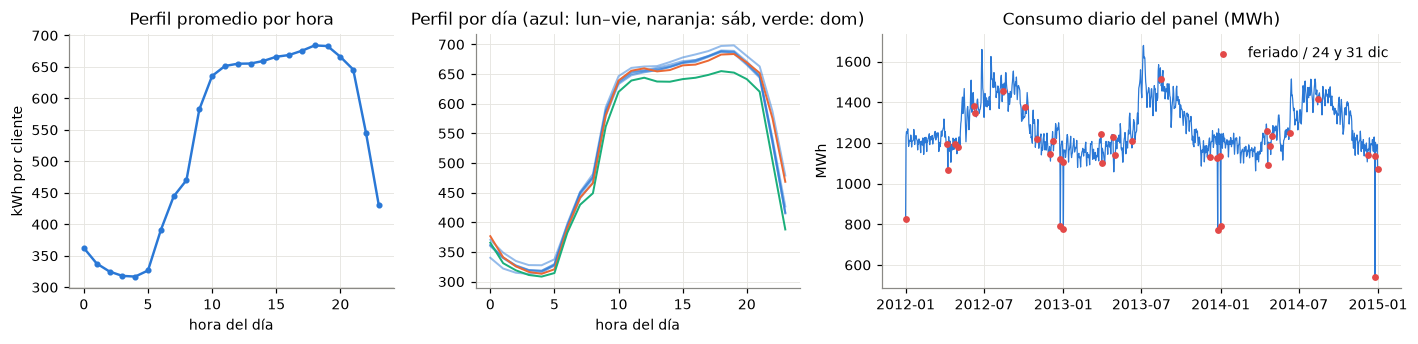

consumo relativo por día de la semana: {'lun': 0.9959999918937683, 'mar': 1.00600004196167, 'mié': 1.0019999742507935, 'jue': 1.003999948501587, 'vie': 1.0219999551773071, 'sáb': 1.00600004196167, 'dom': 0.9649999737739563}


In [6]:
pt_hol = holidays.Portugal(years=range(2011, 2016))
HOLIDAYS = {pd.Timestamp(d) for d in pt_hol} | {pd.Timestamp(y, 12, d) for y in range(2011, 2016) for d in (24, 31)}
is_hol = np.array([d in HOLIDAYS for d in T_INDEX.normalize()], dtype=np.float32)
print("feriados 2014:", sorted(d.strftime("%m-%d") for d in HOLIDAYS if d.year == 2014))

total = Y_df.sum(axis=1)
daily = total.resample("D").sum() / 1e3
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), gridspec_kw={"width_ratios": [1, 1, 1.6]})
prof_h = Y_df.mean(axis=1).groupby(T_INDEX.hour).mean()
axes[0].plot(prof_h.index, prof_h.values, color=PAL[0], marker="o", ms=3)
axes[0].set(title="Perfil promedio por hora", xlabel="hora del día", ylabel="kWh por cliente")
dow_names = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
for d in range(7):
    m = Y_df.mean(axis=1)[T_INDEX.dayofweek == d]
    axes[1].plot(range(24), m.groupby(m.index.hour).mean().values, lw=1.3,
                 color=PAL[0] if d < 5 else (PAL[1] if d == 5 else PAL[2]), alpha=0.5 if d < 5 else 1)
axes[1].set(title="Perfil por día (azul: lun–vie, naranja: sáb, verde: dom)", xlabel="hora del día")
axes[2].plot(daily.index, daily.values, color=PAL[0], lw=0.8)
hol_days = [d for d in daily.index if d in HOLIDAYS]
axes[2].scatter(hol_days, daily.loc[hol_days], color=PAL[7], s=12, zorder=3, label="feriado / 24 y 31 dic")
axes[2].set(title="Consumo diario del panel (MWh)", ylabel="MWh")
axes[2].xaxis.set_major_locator(matplotlib.dates.MonthLocator(bymonth=[1, 7]))
axes[2].xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%Y-%m"))
axes[2].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "perfiles.png", dpi=150); plt.show()

dow_table = (Y_df.mean(axis=1).groupby(T_INDEX.dayofweek).mean() / Y_df.mean(axis=1).mean()).round(3)
dow_table.index = dow_names
print("consumo relativo por día de la semana:", dow_table.to_dict())

**Navidad y Año Nuevo.** Se compara el consumo diario del 20-dic al 3-ene contra la mediana de los días
del mismo día de la semana en las 4 semanas previas.

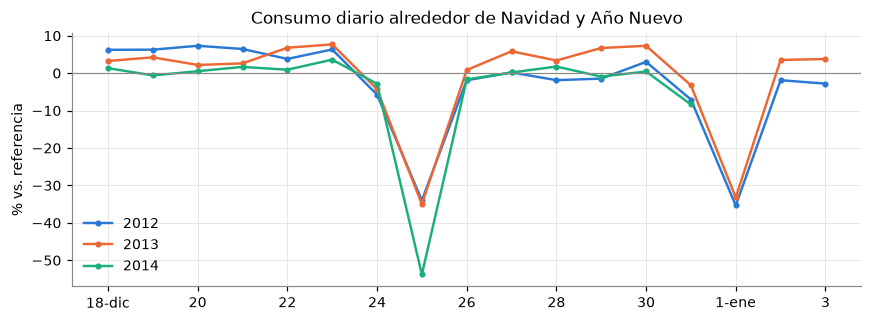

       día  cambio % vs. mismo día de semana
2012-12-24                         -5.700000
2012-12-25                        -34.000000
2012-12-31                         -7.000000
2013-01-01                        -35.299999
2013-12-24                         -4.300000
2013-12-25                        -35.000000
2013-12-31                         -3.200000
2014-01-01                        -33.200001
2014-12-24                         -2.800000
2014-12-25                        -53.799999
2014-12-31                         -8.400000


In [7]:
xmas_rows = []
fig, ax = plt.subplots(figsize=(8, 3))
for k, y in enumerate((2012, 2013, 2014)):
    rng_days = pd.date_range(f"{y}-12-18", f"{y+1}-01-03" if y < 2014 else "2014-12-31")
    ref_days = pd.date_range(f"{y}-11-13", f"{y}-12-11")
    ref = daily.loc[ref_days].groupby(ref_days.dayofweek).median()
    rel = daily.loc[rng_days].values / ref.loc[rng_days.dayofweek].values - 1
    ax.plot(range(len(rng_days)), 100 * rel, marker="o", ms=3, color=PAL[k], label=str(y))
    for d, r in zip(rng_days, rel):
        if (d.month, d.day) in [(12, 24), (12, 25), (12, 31), (1, 1)]:
            xmas_rows.append({"día": d.date(), "cambio % vs. mismo día de semana": round(100 * r, 1)})
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xticks(range(0, 17, 2)); ax.set_xticklabels([f"{d}" for d in ["18-dic", "20", "22", "24", "26", "28", "30", "1-ene", "3"]])
ax.set(ylabel="% vs. referencia", title="Consumo diario alrededor de Navidad y Año Nuevo")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "navidad.png", dpi=150); plt.show()
xmas_df = pd.DataFrame(xmas_rows); print(xmas_df.to_string(index=False))

**Escalas entre clientes.** Se usa el consumo promedio horario en el bloque de entrenamiento.

panel usado (kWh/h): {'mínimo': 20.865, 'mediana': 159.504, 'máximo': 11479.718, 'max/min': 550.178}
panel completo (314) (kWh/h): {'mínimo': 4.33, 'mediana': 148.337, 'máximo': 48818.16}


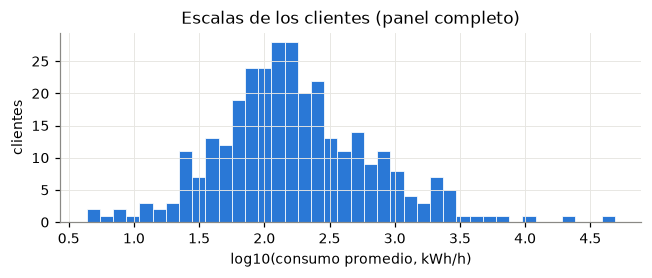

In [8]:
mean_train = Y_kwh[:, :T_TR].mean(1)
scale_stats = {"mínimo": float(mean_train.min()), "mediana": float(np.median(mean_train)),
               "máximo": float(mean_train.max()), "max/min": float(mean_train.max() / mean_train.min())}
mean_all = hourly_all.iloc[:T_TR].mean().values
scale_stats_all = {"mínimo": float(mean_all.min()), "mediana": float(np.median(mean_all)), "máximo": float(mean_all.max())}
print("panel usado (kWh/h):", {k: round(v, 3) for k, v in scale_stats.items()})
print(f"panel completo ({len(kept)}) (kWh/h):", {k: round(v, 3) for k, v in scale_stats_all.items()})
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(np.log10(mean_all), bins=40, color=PAL[0], edgecolor="white", linewidth=0.5)
ax.set(xlabel="log10(consumo promedio, kWh/h)", ylabel="clientes", title="Escalas de los clientes (panel completo)")
fig.tight_layout(); fig.savefig(FIG / "escalas.png", dpi=150); plt.show()

**Normalización propuesta: z-score por serie con estadísticos de entrenamiento.** Las escalas cubren varios
órdenes de magnitud. Con una normalización global, los clientes grandes dominan la pérdida y los pequeños
quedan en ≈ 0. Con z-score por serie, todas las series tienen media 0 y desviación 1, y la red aprende la
*forma* del perfil de forma compartida. Media y desviación se calculan **solo con el bloque de entrenamiento**.
La normalización por ventana (RevIN) se prueba como iteración en la sección 6; ayuda cuando el nivel cambia
dentro de la serie.

La pérdida de todas las redes propias se calcula en kWh y se divide entre la escala MASE de cada cliente:
es la MASE del lote. Así la elección de normalización solo cambia la representación de entrada y salida, no el
objetivo de entrenamiento.

**Covariables de calendario** (conocidas a futuro):

- hora, día de la semana y mes, codificados con **seno/coseno**: son cíclicos (23 h está junto a 0 h) y
  cada uno ocupa 2 columnas en lugar de 24/7/12 *one-hot*;
- feriado como indicador binario.

En LightGBM se usan como enteros categóricos, porque los árboles no necesitan la codificación cíclica.

In [9]:
hours, dows, months = T_INDEX.hour.values, T_INDEX.dayofweek.values, T_INDEX.month.values
CAL = np.stack([np.sin(2 * np.pi * hours / 24), np.cos(2 * np.pi * hours / 24),
                np.sin(2 * np.pi * dows / 7), np.cos(2 * np.pi * dows / 7),
                np.sin(2 * np.pi * (months - 1) / 12), np.cos(2 * np.pi * (months - 1) / 12),
                is_hol], axis=1).astype(np.float32)
CAL_COLS = ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "month_sin", "month_cos", "holiday"]
N_COV = CAL.shape[1]
pd.DataFrame(CAL[:3], columns=CAL_COLS, index=T_INDEX[:3]).round(3)

,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,holiday
2012-01-01 00:00:00,0.000,1.000,-0.782,0.623,0.0,1.0,1.0
2012-01-01 01:00:00,0.259,0.966,-0.782,0.623,0.0,1.0,1.0
2012-01-01 02:00:00,0.500,0.866,-0.782,0.623,0.0,1.0,1.0


**Escala MASE.** Para cada cliente: el MAE dentro de la muestra del *seasonal naive* de 24 h en el bloque de
entrenamiento. Una MASE < 1 significa mejor que repetir el día anterior (dentro de la muestra).

In [10]:
MASE_SCALE = np.abs(Y_kwh[:, 24:T_TR] - Y_kwh[:, :T_TR - 24]).mean(1).astype(np.float32)
print("escala MASE (kWh): min %.3f mediana %.3f max %.1f" % (MASE_SCALE.min(), np.median(MASE_SCALE), MASE_SCALE.max()))

escala MASE (kWh): min 1.031 mediana 13.183 max 736.0


## 3. `Dataset` de ventanas deslizantes

Cada ventana empieza en `t0`:

- entrada `X = [y, calendario](t0 … t0+L−1)`, de forma `(L, 1 + 7)`;
- covariables futuras `fut = calendario(t0+L … t0+L+H−1)`, de forma `(H, 7)`;
- objetivo `y(t0+L … t0+L+H−1)`, de forma `(H,)`.

Una ventana pertenece a un bloque si **todo su objetivo** cae dentro del bloque. La entrada puede venir del
bloque anterior: ese dato ya existe cuando se emite el pronóstico. `__getitems__` arma el lote completo con
indexación vectorizada en la GPU, y el `DataLoader` lo usa directamente sin recorrer las ventanas una por una.

In [11]:
class WindowDataset(Dataset):
    """Ventanas deslizantes sobre todas las series del panel.

    Ys: tensor (n_series, T) ya normalizado. C: tensor (T, n_cov) de calendario.
    t0s: posiciones de inicio de la ventana de entrada (compartidas por todas las series).
    Devuelve X (L, 1+n_cov), fut (H, n_cov), y (H,) y el índice de la serie.
    """
    def __init__(self, Ys, C, t0s, L, H, series=None):
        self.Ys, self.C, self.L, self.H = Ys, C, L, H
        dev = Ys.device
        self.t0s = torch.as_tensor(np.asarray(t0s), device=dev, dtype=torch.long)
        self.series = (torch.arange(Ys.shape[0], device=dev) if series is None
                       else torch.as_tensor(np.asarray(series), device=dev, dtype=torch.long))
        self.ar_in = torch.arange(L, device=dev)
        self.ar_out = torch.arange(L, L + H, device=dev)

    def __len__(self):
        return len(self.series) * len(self.t0s)

    def __getitems__(self, ks):
        ks = torch.as_tensor(ks, device=self.Ys.device, dtype=torch.long)
        i = self.series[ks // len(self.t0s)]
        t0 = self.t0s[ks % len(self.t0s)]
        tin, tout = t0[:, None] + self.ar_in, t0[:, None] + self.ar_out
        x = torch.cat([self.Ys[i[:, None], tin][..., None], self.C[tin]], dim=-1)
        return x, self.C[tout], self.Ys[i[:, None], tout], i

    def __getitem__(self, k):
        x, fut, y, i = self.__getitems__([k])
        return x[0], fut[0], y[0], i[0]

def split_t0s(split, L, H, stride=1, hist_start=0):
    """Inicios de ventana cuyo objetivo cae completo en el bloque."""
    lo, hi = {"train": (hist_start, T_TR), "val": (T_TR, T_VA), "test": (T_VA, T)}[split]
    first_target = max(lo, hist_start + L)
    return np.arange(first_target, hi - H + 1, stride) - L

def split_origins(split, H=24):
    """Orígenes diarios (00:00) del backtest: val = 92 en jul–sep, test = 92 en oct–dic (86 con H=168)."""
    lo, hi = (T_TR, T_VA) if split == "val" else (T_VA, T)
    return np.arange(lo, hi - H + 1, 24)

L0 = 168
counts = {s: len(split_t0s(s, L0, H)) for s in ("train", "val", "test")}
win_table = pd.DataFrame({"ventanas por serie": counts,
                          f"panel usado ({N_SER})": {k: v * N_SER for k, v in counts.items()},
                          f"panel completo ({len(kept)})": {k: v * len(kept) for k, v in counts.items()}})
print(win_table)
_ds = WindowDataset(torch.tensor(Y_kwh), torch.tensor(CAL), split_t0s("train", L0, H), L0, H)
_x, _f, _y, _i = next(iter(DataLoader(_ds, batch_size=32, shuffle=True, collate_fn=lambda b: b)))
print("X:", tuple(_x.shape), "fut:", tuple(_f.shape), "y:", tuple(_y.shape), "| len(dataset) =", len(_ds))

       ventanas por serie  panel usado (100)  panel completo (314)
train               21697            2169700               6812858
val                  2185             218500                686090
test                 2185             218500                686090
X: (32, 168, 8) fut: (32, 24, 7) y: (32, 24) | len(dataset) = 2169700


## 3b. Auditoría de fugas

Cada fuga vista en clase se revisa con una aserción ejecutable. La prueba (iv) se repite con un modelo
entrenado más abajo: si se alteran los datos posteriores al origen, el pronóstico no cambia.

In [12]:
# (i) Split aleatorio de ventanas: los bloques son cronológicos y no se mezclan.
tr_t0, va_t0, te_t0 = (split_t0s(s, L0, H) for s in ("train", "val", "test"))
assert tr_t0.max() + L0 + H <= T_TR <= va_t0.min() + L0          # último objetivo de train < primer objetivo de val
assert va_t0.max() + L0 + H <= T_VA <= te_t0.min() + L0
print("(i) objetivo train termina en", T_INDEX[tr_t0.max() + L0 + H - 1], "| val empieza", T_INDEX[va_t0.min() + L0],
      "| test empieza", T_INDEX[te_t0.min() + L0])

# (ii) Escalar con toda la serie: los estadísticos salen solo de [hist_start, train_end).
def norm_stats(Y, mode, train_end, hist_start=0):
    seg = Y[:, hist_start:train_end].astype(np.float64)
    if mode == "series":
        return seg.mean(1), seg.std(1) + 1e-3
    if mode == "global":
        return np.full(len(Y), seg.mean()), np.full(len(Y), seg.std())
    return np.zeros(len(Y)), np.full(len(Y), seg.std())            # "window": RevIN normaliza dentro del modelo
Y_corrupt = Y_kwh.copy(); Y_corrupt[:, T_TR:] = 1e6
assert all(np.allclose(a, b) for a, b in zip(norm_stats(Y_kwh, "series", T_TR), norm_stats(Y_corrupt, "series", T_TR)))
print("(ii) z-score con estadísticos de train: idénticos aunque val/test se corrompan con 1e6")

# (iii) Early stopping con la prueba: train_model solo recibe ventanas de validación (objetivos < T_VA).
val_targets_end = split_origins("val").max() + H
assert val_targets_end <= T_VA
print("(iii) el último objetivo usado para early stopping es", T_INDEX[val_targets_end - 1], "< inicio de prueba", T_INDEX[T_VA])

# (iv) Covariables mal alineadas: en el origen o, la entrada termina en o-1 (23:00) y el calendario
#      futuro corresponde exactamente a las horas objetivo.
o = split_origins("test")[0]
ds_chk = WindowDataset(torch.tensor(Y_kwh), torch.tensor(CAL), [o - L0], L0, H)
x, fut, y, _ = ds_chk[0]
assert torch.equal(x[-1, 0], torch.tensor(Y_kwh[0, o - 1])) and torch.equal(y[0], torch.tensor(Y_kwh[0, o]))
assert torch.equal(fut, torch.tensor(CAL[o:o + H]))
print("(iv) origen", T_INDEX[o], "| última entrada", T_INDEX[o - 1], "| objetivo", T_INDEX[o], "→", T_INDEX[o + H - 1])

(i) objetivo train termina en 2014-06-30 23:00:00 | val empieza 2014-07-01 00:00:00 | test empieza 2014-10-01 00:00:00
(ii) z-score con estadísticos de train: idénticos aunque val/test se corrompan con 1e6
(iii) el último objetivo usado para early stopping es 2014-09-30 23:00:00 < inicio de prueba 2014-10-01 00:00:00
(iv) origen 2014-10-01 00:00:00 | última entrada 2014-09-30 23:00:00 | objetivo 2014-10-01 00:00:00 → 2014-10-01 23:00:00


## 4. Protocolo de validación: `backtest(modelo)` y métricas

Todos los modelos implementan la misma interfaz `Forecaster`:

- `fit(train_end, val_end, hist_start)`: entrena con datos `< train_end` y usa `[train_end, val_end)` para
  early stopping;
- `predict(origins, H)`: devuelve un arreglo `(n_series, n_origins, H)` en kWh y, si el modelo es
  probabilístico, también sus cuantiles.

`backtest` entrena una sola vez con datos hasta el 2014-09-30 (train hasta junio y validación jul–sep para
early stopping) y pronostica los 92 orígenes de prueba. En cada origen el modelo solo ve datos hasta las 23:00
del día anterior. Con `retrain="monthly"` vuelve a entrenar al inicio de octubre, noviembre y diciembre con
ventana expandible: todo lo anterior al mes, y los 92 días previos como validación.

Las métricas se calculan en kWh sobre todos los clientes y orígenes. El MAPE excluye las horas con consumo
real igual a cero, porque ahí no está definido.

In [13]:
VAL_DAYS = T_VA - T_TR                                    # 2208 h = 92 días

def truth(origins, H):
    return Y_kwh[:, origins[:, None] + np.arange(H)]       # (n, n_o, H)

def pinball(Y, q_pred, levels, scale):
    out = []
    for q, P in zip(levels, q_pred):
        d = Y - P
        out.append((np.maximum(q * d, (q - 1) * d) / scale[:, None, None]).mean())
    return float(np.mean(out))

def evaluate(Y, P, origins, Q=None, series=None):
    s = MASE_SCALE if series is None else MASE_SCALE[series]
    E = P - Y; A = np.abs(E)
    t = origins[:, None] + np.arange(Y.shape[2])
    dates = T_INDEX[t.ravel()].normalize().values.reshape(t.shape)
    xmas = (dates >= np.datetime64("2014-12-22")) & (dates <= np.datetime64("2014-12-28"))
    nz = Y > 0
    m = {"MAE": float(A.mean()), "RMSE": float(np.sqrt((E ** 2).mean())),
         "WAPE": float(A.sum() / np.abs(Y).sum()),
         "MAPE": float((A[nz] / Y[nz]).mean() * 100),
         "MASE": float((A / s[:, None, None]).mean()),
         "MAE_cliente": A.mean((1, 2)), "RMSE_cliente": np.sqrt((E ** 2).mean((1, 2))),
         "MASE_cliente": A.mean((1, 2)) / s, "MAPE_cliente": np.array([(A[i][nz[i]] / Y[i][nz[i]]).mean() * 100 for i in range(len(Y))]),
         "MAE_paso": A.mean((0, 1)), "MASE_paso": (A / s[:, None, None]).mean((0, 1)),
         "MAE_hora": pd.Series(A.mean(0).ravel()).groupby(T_INDEX[t.ravel()].hour).mean().values}
    if xmas.any():
        m["MASE_navidad"] = float((A / s[:, None, None])[:, xmas].mean())
        m["MAE_navidad"] = float(A[:, xmas].mean())
    if Q is not None:
        levels = sorted(Q)
        m["pinball"] = pinball(Y, [Q[q] for q in levels], levels, s)
        m["cobertura_80"] = float(((Y >= Q[0.1]) & (Y <= Q[0.9])).mean())
    return m

class Forecaster:
    name, family, L, strategy, covariates, hardware = "base", "", 0, "multi-salida", "no", HARDWARE_GPU
    n_params = n_trainable = None
    train_time = 0.0; peak_mem = None; fitted = False
    def fit(self, train_end=T_TR, val_end=T_VA, hist_start=0): raise NotImplementedError
    def predict(self, origins, H): raise NotImplementedError

def backtest(model, split="test", H=24, retrain=None):
    """Evalúa un Forecaster con origen móvil diario y devuelve métricas, pronósticos y tiempos."""
    origins = split_origins(split, H)
    Q = None
    if retrain == "monthly":
        assert split == "test"
        P, Qs, train_time, infer_time = [], [], 0.0, 0.0
        month = T_INDEX[origins].month
        for mth in sorted(set(month), key=lambda m: (m < 10, m)):
            o_m = origins[month == mth]
            start = o_m[0]
            t0 = time.time(); model.fit(train_end=start - VAL_DAYS, val_end=start); train_time += time.time() - t0
            t0 = time.time(); p, q = model.predict(o_m, H); infer_time += time.time() - t0
            P.append(p); Qs.append(q)
        P = np.concatenate(P, axis=1)
        if Qs[0] is not None:
            Q = {k: np.concatenate([q[k] for q in Qs], axis=1) for k in Qs[0]}
    else:
        if not model.fitted:
            t0 = time.time(); model.fit(); model.fitted = True
            model.train_time = 0.0 if getattr(model, "zero_shot", False) else time.time() - t0
        train_time = model.train_time
        t0 = time.time(); P, Q = model.predict(origins, H); infer_time = time.time() - t0
    P = np.maximum(np.asarray(P, dtype=np.float32), 0)    # el consumo no puede ser negativo
    Y = truth(origins, H)
    res = {"name": model.name, "split": split, "H": H, "retrain": retrain, "origins": origins, "P": P, "Q": Q,
           "metrics": evaluate(Y, P, origins, Q), "train_time": train_time, "infer_time": infer_time,
           "family": model.family, "L": model.L, "strategy": model.strategy, "covariates": model.covariates,
           "n_params": model.n_params, "n_trainable": model.n_trainable, "hardware": model.hardware,
           "peak_mem_MB": model.peak_mem}
    m = res["metrics"]
    print(f"[{split} H={H}{' reentreno mensual' if retrain else ''}] {model.name:<16} MASE {m['MASE']:.3f} "
          f"MAE {m['MAE']:.2f} WAPE {m['WAPE']:.3f} | train {train_time:.0f}s infer {infer_time:.1f}s")
    return res

def mem_mb():
    return torch.mps.driver_allocated_memory() / 2**20 if DEVICE.type == "mps" else None

RESULTS = {}            # RESULTS[(nombre, split, H, retrain)] = resultado de backtest

def run_backtests(key, factory, splits=(("val", 24), ("test", 24))):
    """Entrena una vez (con caché) y evalúa en validación y prueba con el mismo modelo."""
    def job():
        model = factory()
        return [backtest(model, s, h) for s, h in splits]
    out = cached(key, job)
    for r in out:
        RESULTS[(r["name"], r["split"], r["H"], r["retrain"])] = r
    return out

## 5. Modelos

### 5.1 Baselines (StatsForecast) y LightGBM, en un hilo de CPU en paralelo

- **StatsForecast**: `Naive`, `SeasonalNaive(24)`, `SeasonalNaive(168)` y `MSTL(season_length=[24, 168])`
  con tendencia `AutoETS`, todos con `cross_validation(h, n_windows=92, step_size=24, refit=False)`. Con
  `refit=False` se ajustan una sola vez con los datos previos al primer origen y en los siguientes solo se
  actualizan con los datos nuevos. MSTL usa las últimas 12 semanas como entrada.
- **LightGBM global (directo)**: una fila por (cliente, origen, paso h). Sus variables son:
  - los rezagos 1–24 respecto del origen (las últimas 24 horas observadas);
  - el rezago 168 de la hora objetivo (siempre ≤ origen porque H ≤ 24);
  - el paso `h`, el calendario de la hora objetivo y el consumo medio del cliente.

  Objetivo y rezagos se dividen entre la escala MASE del cliente, así que la pérdida L1 de LightGBM es
  directamente la MASE.

El trabajo de CPU arranca aquí en un `ThreadPoolExecutor` y corre en paralelo con el entrenamiento de las
redes en la GPU. Se recoge en la sección 7.

In [14]:
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, MSTL, AutoETS

def long_df(t_end, t_start=0, series=None):
    idx = range(N_SER) if series is None else series
    ds = T_INDEX[t_start:t_end]
    return pd.DataFrame({"unique_id": np.repeat([str(i) for i in idx], len(ds)),
                         "ds": np.tile(ds.values, len(idx)),
                         "y": Y_kwh[list(idx), t_start:t_end].ravel()})

def cv_to_array(cv, col, origins, H):
    cv = cv.copy(); cv["uid"] = cv["unique_id"].astype(int)
    cv = cv.sort_values(["uid", "cutoff", "ds"])
    arr = cv[col].values.reshape(N_SER, -1, H)
    assert arr.shape[1] == len(origins)
    return arr

class StatsModel(Forecaster):
    hardware = HARDWARE_CPU
    def __init__(self, name, model, input_size=None):
        self.name, self.model, self.input_size = name, model, input_size
        self.family, self.L, self.strategy = "Baseline", input_size or 0, "directa"
        self.n_params = self.n_trainable = 0
    def fit(self, train_end=T_TR, val_end=T_VA, hist_start=0):
        self.cutoff = val_end                           # sin hiperparámetros: se ajusta con todo lo previo al origen
        t0 = time.time()
        if "MSTL" in self.name:                         # tiempo de un ajuste, para la tabla
            start = val_end - (self.input_size or val_end)
            StatsForecast([self.model], freq="h", n_jobs=CPU_THREADS).fit(long_df(val_end, start))
        self.fit_seconds = time.time() - t0
    def predict(self, origins, H):
        end = origins[-1] + H
        start = 0 if self.input_size is None else origins[0] - self.input_size
        sf = StatsForecast([self.model], freq="h", n_jobs=CPU_THREADS)
        cv = sf.cross_validation(df=long_df(end, start), h=H, n_windows=len(origins), step_size=24, refit=False)
        col = [c for c in cv.columns if c not in ("unique_id", "ds", "cutoff", "y")][0]
        return cv_to_array(cv, col, origins, H), None

STATS_SPECS = {
    "Naive": lambda: StatsModel("Naive", Naive()),
    "SeasonalNaive24": lambda: StatsModel("SeasonalNaive24", SeasonalNaive(24)),
    "SeasonalNaive168": lambda: StatsModel("SeasonalNaive168", SeasonalNaive(168)),
    "MSTL": lambda: StatsModel("MSTL", MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model="ZZN")),
                               input_size=24 * 7 * (3 if FAST else 12)),
}

# ---- LightGBM global directo ----
LGB_LAGS = list(range(1, 25))
def lgb_rows(origins, series=None, H=24, with_y=True):
    idx = np.arange(N_SER) if series is None else np.asarray(series)
    s = MASE_SCALE[idx]
    I, O, Hh = np.meshgrid(idx, origins, np.arange(H), indexing="ij")
    I, O, Hh = I.ravel(), O.ravel(), Hh.ravel()
    tgt = O + Hh
    sc = MASE_SCALE[I]
    X = {f"lag{k}": Y_kwh[I, O - k] / sc for k in LGB_LAGS}
    X["lag168_t"] = Y_kwh[I, tgt - 168] / sc
    X.update({"h": Hh, "hour": hours[tgt], "dow": dows[tgt], "month": months[tgt], "holiday": is_hol[tgt],
              "nivel": np.log1p(mean_train[I])})
    X = pd.DataFrame(X)
    y = Y_kwh[I, tgt] / sc if with_y else None
    return X, y, sc

class LightGBMModel(Forecaster):
    hardware = HARDWARE_CPU
    def __init__(self, months=30, num_leaves=255, name="LightGBM"):
        self.name, self.months, self.num_leaves = name, months, num_leaves
        self.family, self.L, self.strategy, self.covariates = "Árboles", 168, "directa (h como variable)", "sí"
    def fit(self, train_end=T_TR, val_end=T_VA, hist_start=None):
        start = T_INDEX.get_loc(T_INDEX[train_end] - pd.DateOffset(months=self.months)) if self.months < 30 else 0
        o_tr = np.arange(max(start, 168), train_end - 23, 24)
        o_va = np.arange(train_end, val_end - 23, 24)
        Xtr, ytr, _ = lgb_rows(o_tr); Xva, yva, _ = lgb_rows(o_va)
        params = dict(objective="l1", learning_rate=0.05, num_leaves=self.num_leaves, min_data_in_leaf=100,
                      feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, num_threads=CPU_THREADS,
                      verbose=-1, seed=SEED)
        dtr = lgb.Dataset(Xtr, ytr, categorical_feature=["hour", "dow"])
        dva = lgb.Dataset(Xva, yva, reference=dtr)
        self.booster = lgb.train(params, dtr, num_boost_round=50 if FAST else 3000, valid_sets=[dva],
                                 callbacks=[lgb.early_stopping(100, verbose=False)])
        self.n_rows = len(Xtr)
        self.n_params = self.n_trainable = int(self.booster.num_trees() * self.num_leaves)   # hojas (aprox.)
    def predict(self, origins, H):
        X, _, sc = lgb_rows(origins, H=H, with_y=False)
        return (self.booster.predict(X, num_threads=CPU_THREADS) * sc).reshape(N_SER, len(origins), H), None

def cpu_jobs():
    """Baselines y LightGBM (CPU). Corre en un hilo mientras la GPU entrena las redes."""
    out = {}
    for name, f in STATS_SPECS.items():
        out[name] = run_backtests(f"stats_{name}", f, (("val", 24), ("test", 24), ("test", 168)))
    for m in (3, 12, 30):                     # iteración de historia de entrenamiento (solo validación)
        nm = "LightGBM" if m == 30 else f"LightGBM_{m}m"
        splits = (("val", 24), ("test", 24)) if m == 30 else (("val", 24),)
        out[nm] = run_backtests(f"lgb_{m}m", lambda m=m, nm=nm: LightGBMModel(months=m, name=nm), splits)
    out["LightGBM_63hojas"] = run_backtests("lgb_63", lambda: LightGBMModel(num_leaves=63, name="LightGBM_63hojas"), (("val", 24),))
    return out

CPU_POOL = ThreadPoolExecutor(max_workers=1)
cpu_future = CPU_POOL.submit(cpu_jobs)
print("trabajo de CPU lanzado en paralelo")

trabajo de CPU lanzado en paralelo


### 5.2 Implementaciones propias en PyTorch

Todas reciben `x (B, L, 8)` y `fut (B, H, 7)` y devuelven `(B, H)`.

- **MLP multi-salida**: aplana la ventana y el calendario futuro y aplica 2 capas ocultas.
- **DLinear**: descompone la entrada en tendencia (media móvil de 25) y estacionalidad, con una capa lineal
  `L→H` para cada una.
- **NLinear**: resta el último valor, aplica una capa lineal `L→H` y lo vuelve a sumar.
- **LSTM multi-salida**: `nn.LSTM` sobre la ventana; el estado final `h_n[-1]`, concatenado con el calendario
  futuro, pasa por una capa densa que devuelve los 24 pasos.
- **LSTM autorregresiva**: predice un paso. En entrenamiento usa *teacher forcing* sobre toda la secuencia
  `L+H−1`. En inferencia realimenta su predicción 24 veces junto con el calendario de la hora siguiente.
- **Seq2seq**: un encoder LSTM y un decoder LSTM que en cada paso recibe `[ŷ_{t−1}, calendario_t]`.
  Entrena con *teacher forcing* (probabilidad 0.5).
- **RevIN** (opcional, `norm="window"`): normaliza cada ventana con su media y desviación y desnormaliza la
  salida, con un afín aprendible.

In [15]:
class RevIN(nn.Module):
    def __init__(self, eps=1e-4):
        super().__init__(); self.g = nn.Parameter(torch.ones(1)); self.b = nn.Parameter(torch.zeros(1)); self.eps = eps
    def stats(self, y):
        self.mu = y.mean(1, keepdim=True).detach()
        self.sd = (y.var(1, keepdim=True, unbiased=False) + self.eps).sqrt().detach()
    def norm(self, y): return (y - self.mu) / self.sd * self.g + self.b
    def denorm(self, y): return (y - self.b) / (self.g + self.eps) * self.sd + self.mu

class MLPCore(nn.Module):
    def __init__(self, L, H, hidden=512, dropout=0.1, **_):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(L * (1 + N_COV) + H * N_COV, hidden), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, H))
    def forward(self, x, fut, *_):
        return self.net(torch.cat([x.flatten(1), fut.flatten(1)], 1))

class DLinearCore(nn.Module):
    def __init__(self, L, H, kernel=25, **_):
        super().__init__(); self.k = kernel
        self.lin_s, self.lin_t = nn.Linear(L, H), nn.Linear(L, H)
    def forward(self, x, fut, *_):
        y = x[..., 0]
        pad = F.pad(y[:, None], ((self.k - 1) // 2, self.k // 2), mode="replicate")
        trend = F.avg_pool1d(pad, self.k, stride=1)[:, 0]
        return self.lin_s(y - trend) + self.lin_t(trend)

class NLinearCore(nn.Module):
    def __init__(self, L, H, **_):
        super().__init__(); self.lin = nn.Linear(L, H)
    def forward(self, x, fut, *_):
        y = x[..., 0]; last = y[:, -1:]
        return self.lin(y - last) + last

class TCNCore(nn.Module):
    """Convoluciones causales dilatadas (kernel 2, dilataciones 1…128 → campo receptivo 256 h) con residuales;
    el último estado y el calendario futuro pasan a una cabeza lineal que emite los H pasos."""
    def __init__(self, L, H, hidden=64, dropout=0.1, kernel=2, dilations=(1, 2, 4, 8, 16, 32, 64, 128), **_):
        super().__init__(); self.k, self.dil = kernel, dilations
        self.convs = nn.ModuleList([nn.Conv1d(1 + N_COV if i == 0 else hidden, hidden, kernel, dilation=d)
                                    for i, d in enumerate(dilations)])
        self.inp = nn.Conv1d(1 + N_COV, hidden, 1)       # residual del primer bloque (cambia de canales)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Sequential(nn.Linear(hidden + H * N_COV, hidden), nn.ReLU(), nn.Linear(hidden, H))
    def forward(self, x, fut, *_):
        z = x.transpose(1, 2)                            # (B, canales, L)
        for i, (conv, d) in enumerate(zip(self.convs, self.dil)):
            out = self.drop(F.relu(conv(F.pad(z, ((self.k - 1) * d, 0)))))   # padding solo a la izquierda: causal
            z = out + (self.inp(z) if i == 0 else z)
        return self.head(torch.cat([z[:, :, -1], fut.flatten(1)], 1))

class LSTMMOCore(nn.Module):
    def __init__(self, L, H, hidden=128, layers=2, dropout=0.1, **_):
        super().__init__()
        self.lstm = nn.LSTM(1 + N_COV, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0)
        self.head = nn.Sequential(nn.Linear(hidden + H * N_COV, hidden), nn.ReLU(), nn.Linear(hidden, H))
    def forward(self, x, fut, *_):
        _, (h_n, _) = self.lstm(x)                       # h_n: (layers, B, hidden)
        return self.head(torch.cat([h_n[-1], fut.flatten(1)], 1))

class LSTMARCore(nn.Module):
    """Entrada en t: [y_t, calendario_{t+1}] → ŷ_{t+1}."""
    def __init__(self, L, H, hidden=128, layers=2, dropout=0.1, **_):
        super().__init__(); self.H = H
        self.lstm = nn.LSTM(1 + N_COV, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x, fut, y_tf=None, tf_ratio=0.0, train_seq=False):
        cov_next = torch.cat([x[:, 1:, 1:], fut[:, :1]], 1)
        inp = torch.cat([x[..., :1], cov_next], -1)
        if train_seq:                                     # teacher forcing sobre L+H−1 pasos
            tail = torch.cat([y_tf[:, :-1, None], fut[:, 1:]], -1)
            out, _ = self.lstm(torch.cat([inp, tail], 1))
            return self.head(out)[..., 0]
        out, hc = self.lstm(inp)
        yk = self.head(out[:, -1]); preds = [yk]
        for k in range(1, self.H):                       # realimenta su propia predicción
            out, hc = self.lstm(torch.cat([yk, fut[:, k]], -1)[:, None], hc)
            yk = self.head(out[:, -1]); preds.append(yk)
        return torch.cat(preds, 1)

class Seq2SeqCore(nn.Module):
    def __init__(self, L, H, hidden=128, layers=2, dropout=0.1, **_):
        super().__init__(); self.H = H
        self.enc = nn.LSTM(1 + N_COV, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0)
        self.dec = nn.LSTM(1 + N_COV, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x, fut, y_tf=None, tf_ratio=0.0, **_):
        _, hc = self.enc(x)
        yprev, outs = x[:, -1, :1], []
        for k in range(self.H):
            out, hc = self.dec(torch.cat([yprev, fut[:, k]], -1)[:, None], hc)
            yk = self.head(out[:, 0]); outs.append(yk)
            if y_tf is not None and tf_ratio > 0:
                use_true = torch.rand(yk.shape[0], 1, device=yk.device) < tf_ratio
                yprev = torch.where(use_true, y_tf[:, k:k + 1], yk)
            else:
                yprev = yk
        return torch.cat(outs, 1)

CORES = {"mlp": MLPCore, "dlinear": DLinearCore, "nlinear": NLinearCore, "tcn": TCNCore,
         "lstm_mo": LSTMMOCore, "lstm_ar": LSTMARCore, "seq2seq": Seq2SeqCore}

class Net(nn.Module):
    def __init__(self, kind, L, H, revin=False, **kw):
        super().__init__()
        self.kind, self.core, self.revin = kind, CORES[kind](L, H, **kw), revin
        if revin: self.rv = RevIN()
    def forward(self, x, fut, y_tf=None, tf_ratio=0.0, train_seq=False):
        if self.revin:
            self.rv.stats(x[..., 0])
            x = torch.cat([self.rv.norm(x[..., :1].squeeze(-1))[..., None], x[..., 1:]], -1)
            y_tf = self.rv.norm(y_tf) if y_tf is not None else None
        kw = {"train_seq": train_seq} if self.kind == "lstm_ar" else {}
        out = self.core(x, fut, y_tf, tf_ratio, **kw)
        return self.rv.denorm(out) if self.revin else out

**Entrenamiento.** Se usa:

- Adam con *clipping* de gradiente en 1.0;
- lotes muestreados al azar de todas las ventanas de entrenamiento (80 000 ventanas por epoch, máximo 20 epochs; el mismo presupuesto para todas las iteraciones);
- pérdida = MASE del lote, en kWh dividido entre la escala de cada cliente;
- early stopping con paciencia 4 sobre la MASE de validación, conservando los mejores pesos.

Al final de cada epoch se registran la pérdida de train y de validación, el MAE (kWh) y la MASE de validación,
el tiempo y la memoria de la GPU (`torch.mps.driver_allocated_memory`, muestreada cada 50 pasos).

In [16]:
BASE_CFG = dict(kind="lstm_mo", L=168, H=24, hidden=128, layers=2, dropout=0.1, norm="series",
                lr=1e-3, bs=512, months=30, tf=0.5, max_epochs=3 if FAST else 20, patience=4,
                spe=3000 if FAST else 80_000)
CAL_T = torch.tensor(CAL, device=DEVICE)
SCALE_T = torch.tensor(MASE_SCALE, device=DEVICE)

def hist_start_idx(months, train_end):
    if months >= 30: return 0
    return T_INDEX.get_loc(T_INDEX[train_end] - pd.DateOffset(months=months))

def predict_net(net, Ys, a_t, b_t, cfg, origins, series=None):
    """Pronóstico (n_series, n_origins, H) en kWh para todos los orígenes, en lotes."""
    net.eval()
    ds = WindowDataset(Ys, CAL_T, origins - cfg["L"], cfg["L"], cfg["H"], series=series)
    out, bs = [], 256 if cfg["kind"] in ("lstm_ar", "seq2seq") else 1024   # los recursivos guardan H estados
    with torch.no_grad():
        for k in range(0, len(ds), bs):
            x, fut, _, i = ds.__getitems__(torch.arange(k, min(k + bs, len(ds)), device=DEVICE))
            out.append(net(x, fut) * b_t[i, None] + a_t[i, None])
    n = len(ds.series)
    return torch.cat(out).reshape(n, len(origins), cfg["H"]).cpu().numpy()

class TorchModel(Forecaster):
    def __init__(self, name, seed=SEED, series=None, **cfg):
        self.name, self.seed, self.series = name, seed, series
        self.cfg = {**BASE_CFG, **cfg}
        c = self.cfg
        self.family = {"mlp": "MLP", "dlinear": "Lineal", "nlinear": "Lineal", "tcn": "Convolucional", "lstm_mo": "Recurrente",
                       "lstm_ar": "Recurrente", "seq2seq": "Encoder–decoder"}[c["kind"]]
        self.L = c["L"]
        self.strategy = {"lstm_ar": "autorregresiva", "seq2seq": "encoder–decoder"}.get(c["kind"], "multi-salida")
        self.covariates = "no" if c["kind"] in ("dlinear", "nlinear") else "sí (calendario)"

    def fit(self, train_end=T_TR, val_end=T_VA, hist_start=None):
        c = self.cfg; set_seed(self.seed)
        gc.collect()
        if DEVICE.type == "mps": torch.mps.empty_cache()  # libera la memoria que dejaron los modelos anteriores
        hs = hist_start_idx(c["months"], train_end) if hist_start is None else hist_start
        a, b = norm_stats(Y_kwh, c["norm"], train_end, hs)
        self.a_t = torch.tensor(a, device=DEVICE, dtype=torch.float32)
        self.b_t = torch.tensor(b, device=DEVICE, dtype=torch.float32)
        self.Ys = (torch.tensor(Y_kwh, device=DEVICE) - self.a_t[:, None]) / self.b_t[:, None]
        t0s = np.arange(hs, train_end - c["L"] - c["H"] + 1)
        ds = WindowDataset(self.Ys, CAL_T, t0s, c["L"], c["H"], series=self.series)
        sampler = RandomSampler(ds, replacement=False, num_samples=min(c["spe"], len(ds)))
        dl = DataLoader(ds, batch_size=c["bs"], sampler=sampler, collate_fn=lambda b: b)
        net = Net(c["kind"], c["L"], c["H"], revin=c["norm"] == "window", hidden=c["hidden"],
                  layers=c["layers"], dropout=c["dropout"]).to(DEVICE)
        opt = torch.optim.Adam(net.parameters(), lr=c["lr"])
        self.n_params = sum(p.numel() for p in net.parameters())
        self.n_trainable = sum(p.numel() for p in net.parameters() if p.requires_grad)
        o_val = np.arange(train_end, val_end - c["H"] + 1, 24)
        Yv = Y_kwh[:, o_val[:, None] + np.arange(c["H"])]
        if self.series is not None: Yv = Yv[self.series]
        sc = MASE_SCALE if self.series is None else MASE_SCALE[self.series]
        hist, best, best_state, bad, peak = [], np.inf, None, 0, 0
        max_epochs = c["max_epochs"] if not c.get("fixed_epochs") else c["fixed_epochs"]
        for ep in range(max_epochs):
            net.train(); t_ep = time.time(); tot, nb = 0.0, 0
            for step, (x, fut, y, i) in enumerate(dl):
                if c["kind"] == "lstm_ar":
                    pred = net(x, fut, y_tf=y, train_seq=True); target = torch.cat([x[:, 1:, 0], y], 1)
                else:
                    pred = net(x, fut, y_tf=y, tf_ratio=c["tf"] if c["kind"] == "seq2seq" else 0.0); target = y
                loss = ((pred - target).abs() * (self.b_t[i] / SCALE_T[i])[:, None]).mean()
                opt.zero_grad(set_to_none=True); loss.backward()
                nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
                tot += loss.item(); nb += 1
                if step % 50 == 0: peak = max(peak, mem_mb() or 0)
            ep_time = time.time() - t_ep
            if val_end > train_end:
                Pv = np.maximum(predict_net(net, self.Ys, self.a_t, self.b_t, c, o_val, self.series), 0)
                Av = np.abs(Pv - Yv)
                v_mae, v_mase = float(Av.mean()), float((Av / sc[:, None, None]).mean())
            else:
                v_mae = v_mase = np.nan
            hist.append({"epoch": ep + 1, "train_loss": tot / nb, "val_loss": v_mase, "val_MAE": v_mae,
                         "val_MASE": v_mase, "epoch_s": ep_time})
            if val_end > train_end:
                if v_mase < best - 1e-4:
                    best, bad = v_mase, 0
                    best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
                else:
                    bad += 1
                    if bad >= c["patience"]: break
        if best_state is not None: net.load_state_dict(best_state)
        self.net, self.history, self.peak_mem = net, hist, peak
        self.best_epoch = int(np.nanargmin([h["val_MASE"] for h in hist]) + 1) if val_end > train_end else len(hist)
        self.n_windows = len(ds)

    def predict(self, origins, H):
        assert H == self.cfg["H"]
        return predict_net(self.net, self.Ys, self.a_t, self.b_t, self.cfg, origins, self.series), None

**Prueba de fuga (iv) con un modelo entrenado.** Se entrena un NLinear rápido y se reemplazan por ruido todos
los datos posteriores al origen. Los pronósticos deben ser idénticos.

In [17]:
_m = TorchModel("chk", kind="nlinear", max_epochs=1, spe=20_000); _m.fit()
o_chk = split_origins("test")[:5]
p1, _ = _m.predict(o_chk, H)
Ys_backup = _m.Ys.clone()
_m.Ys[:, o_chk[0]:] = torch.randn_like(_m.Ys[:, o_chk[0]:]) * 100       # todo lo posterior al 1er origen
p2, _ = _m.predict(o_chk[:1], H)
assert np.allclose(p1[:, :1], p2), "¡fuga: el pronóstico depende de datos futuros!"
_m.Ys = Ys_backup
print("(iv) el pronóstico del origen", T_INDEX[o_chk[0]], "no cambia al alterar los datos posteriores")
del _m

(iv) el pronóstico del origen 2014-10-01 00:00:00 no cambia al alterar los datos posteriores


## 6. Iteraciones de hiperparámetros (solo validación)

Cada iteración se entrena con datos hasta junio de 2014 y se selecciona por la MASE de validación
(92 orígenes jul–sep). La prueba se usa una sola vez por modelo, con la mejor configuración.

In [18]:
ITER = {}
def run_iter(name, **cfg):
    def job():
        m = TorchModel(name, **cfg)
        r = backtest(m, "val", cfg.get("H", 24))
        return {"name": name, "cfg": m.cfg, "history": m.history, "best_epoch": m.best_epoch,
                "n_params": m.n_params, "n_trainable": m.n_trainable, "train_time": m.train_time,
                "epoch_s": float(np.mean([h["epoch_s"] for h in m.history])), "infer_time": r["infer_time"],
                "peak_mem_MB": m.peak_mem, "val_MASE": r["metrics"]["MASE"], "val_MAE": r["metrics"]["MAE"],
                "n_windows": m.n_windows, "state": {k: v.cpu() for k, v in m.net.state_dict().items()}}
    ITER[name] = cached(f"iter_{name}", job)
    it = ITER[name]
    print(f"{name:<24} val MASE {it['val_MASE']:.4f} | epochs {len(it['history'])} (mejor {it['best_epoch']}) "
          f"| {it['train_time']:.0f}s | params {it['n_params']:,}")
    return it

# Iteración 1: ventana L con la LSTM multi-salida
for L in (48, 168, 336):
    run_iter(f"lstm_mo_L{L}", L=L)

lstm_mo_L48              val MASE 1.0043 | epochs 20 (mejor 20) | 185s | params 243,864
lstm_mo_L168             val MASE 1.0081 | epochs 20 (mejor 19) | 262s | params 243,864
lstm_mo_L336             val MASE 1.0030 | epochs 20 (mejor 18) | 291s | params 243,864


In [19]:
best_L = min((48, 168, 336), key=lambda L: ITER[f"lstm_mo_L{L}"]["val_MASE"])
print("mejor L para la LSTM:", best_L)
# Iteración 2: historia de entrenamiento (3, 12 y 30 meses)
for mo in (3, 12):
    run_iter(f"lstm_mo_L{best_L}_{mo}m", L=best_L, months=mo)
# Iteración 3: normalización global y por ventana (RevIN); la base es z-score por serie
for nm in ("global", "window"):
    run_iter(f"lstm_mo_L{best_L}_{nm}", L=best_L, norm=nm)

mejor L para la LSTM: 336
lstm_mo_L336_3m          val MASE 1.2063 | epochs 20 (mejor 17) | 651s | params 243,864
lstm_mo_L336_12m         val MASE 0.9950 | epochs 20 (mejor 19) | 283s | params 243,864
lstm_mo_L336_global      val MASE 1.5342 | epochs 20 (mejor 19) | 283s | params 243,864
lstm_mo_L336_window      val MASE 0.9873 | epochs 20 (mejor 20) | 758s | params 243,866


In [20]:
def best_of(prefix_names):
    return min(prefix_names, key=lambda n: ITER[n]["val_MASE"])
norm_best = ITER[best_of([f"lstm_mo_L{best_L}", f"lstm_mo_L{best_L}_global", f"lstm_mo_L{best_L}_window"])]["cfg"]["norm"]
# Iteración 4: capacidad, regularización y optimización
for nm, kw in {"h256": dict(hidden=256), "capas1": dict(layers=1),
               "drop03": dict(dropout=0.3), "lr3e-3": dict(lr=3e-3), "bs1024": dict(bs=1024)}.items():
    run_iter(f"lstm_mo_L{best_L}_{norm_best}_{nm}", L=best_L, norm=norm_best, **kw)

lstm_mo_L336_window_h256 val MASE 0.9338 | epochs 20 (mejor 18) | 2769s | params 913,690
lstm_mo_L336_window_capas1 val MASE 1.0172 | epochs 20 (mejor 19) | 281s | params 111,770
lstm_mo_L336_window_drop03 val MASE 0.9981 | epochs 20 (mejor 19) | 287s | params 243,866
lstm_mo_L336_window_lr3e-3 val MASE 0.9478 | epochs 20 (mejor 20) | 291s | params 243,866
lstm_mo_L336_window_bs1024 val MASE 1.0360 | epochs 20 (mejor 19) | 278s | params 243,866


In [21]:
# Modelos propios restantes: ventana L (y normalización por ventana para los lineales)
for L in (168, 336):
    run_iter(f"mlp_L{L}", kind="mlp", L=L)
    run_iter(f"dlinear_L{L}", kind="dlinear", L=L)
    run_iter(f"nlinear_L{L}", kind="nlinear", L=L)
run_iter("dlinear_L336_window", kind="dlinear", L=336, norm="window")
for L in (168, 336):                                     # TCN propia (64 canales, campo receptivo 256 h)
    run_iter(f"tcn_L{L}", kind="tcn", L=L, hidden=64)
for mo in (3, 12):
    run_iter(f"dlinear_L336_{mo}m", kind="dlinear", L=336, months=mo)

mlp_L168                 val MASE 0.9768 | epochs 12 (mejor 8) | 3s | params 213,272
dlinear_L168             val MASE 0.8730 | epochs 18 (mejor 14) | 3s | params 8,112
nlinear_L168             val MASE 0.8733 | epochs 18 (mejor 14) | 3s | params 4,056
mlp_L336                 val MASE 1.0111 | epochs 7 (mejor 6) | 2s | params 385,304
dlinear_L336             val MASE 0.8569 | epochs 20 (mejor 16) | 4s | params 16,176
nlinear_L336             val MASE 0.8616 | epochs 18 (mejor 14) | 3s | params 8,088
dlinear_L336_window      val MASE 0.8592 | epochs 15 (mejor 11) | 7s | params 16,178
tcn_L168                 val MASE 0.9054 | epochs 20 (mejor 20) | 82s | params 75,928
tcn_L336                 val MASE 0.8998 | epochs 20 (mejor 20) | 159s | params 75,928
dlinear_L336_3m          val MASE 0.8744 | epochs 12 (mejor 8) | 2s | params 16,176
dlinear_L336_12m         val MASE 0.8592 | epochs 16 (mejor 12) | 3s | params 16,176


In [22]:
iter_rows = []
for n, it in ITER.items():
    c = it["cfg"]
    iter_rows.append({"iteración": n, "modelo": c["kind"], "L": c["L"], "H": c["H"], "meses": c["months"],
                      "norm": c["norm"], "hidden": c["hidden"] if c["kind"] not in ("dlinear", "nlinear") else "-",
                      "capas": c["layers"] if "lstm" in c["kind"] or c["kind"] == "seq2seq" else "-",
                      "dropout": c["dropout"], "lr": c["lr"], "batch": c["bs"], "params": it["n_params"],
                      "entrenables": it["n_trainable"], "epochs": len(it["history"]), "mejor epoch": it["best_epoch"],
                      "s/epoch": round(it["epoch_s"], 1), "train s": round(it["train_time"], 1),
                      "infer 92 orig. s": round(it["infer_time"], 2), "mem pico MB": round(it["peak_mem_MB"] or 0),
                      "val MAE": round(it["val_MAE"], 3), "val MASE": round(it["val_MASE"], 4)})
iter_df = pd.DataFrame(iter_rows)
iter_df.to_csv(RES / "iteraciones.csv", index=False)
json.dump({n: it["history"] for n, it in ITER.items()}, open(RES / "iteraciones_historia.json", "w"), indent=1)
iter_df

,iteración,modelo,L,H,meses,norm,hidden,capas,dropout,lr,...,params,entrenables,epochs,mejor epoch,s/epoch,train s,infer 92 orig. s,mem pico MB,val MAE,val MASE
0,lstm_mo_L48,lstm_mo,48,24,30,series,128,2,0.1,0.001,...,243864,243864,20,20,8.8,184.6,0.13,3184,39.857,1.0043
1,lstm_mo_L168,lstm_mo,168,24,30,series,128,2,0.1,0.001,...,243864,243864,20,19,12.4,262.2,0.42,9510,39.832,1.0081
2,lstm_mo_L336,lstm_mo,336,24,30,series,128,2,0.1,0.001,...,243864,243864,20,18,14.0,291.3,0.55,5529,39.863,1.0030
3,lstm_mo_L336_3m,lstm_mo,336,24,3,series,128,2,0.1,0.001,...,243864,243864,20,17,25.0,650.8,87.43,18847,48.214,1.2063
4,lstm_mo_L336_12m,lstm_mo,336,24,12,series,128,2,0.1,0.001,...,243864,243864,20,19,13.6,283.1,0.57,17605,39.239,0.9950
5,lstm_mo_L336_global,lstm_mo,336,24,30,global,128,2,0.1,0.001,...,243864,243864,20,19,13.6,283.1,0.55,18947,57.043,1.5342
6,lstm_mo_L336_window,lstm_mo,336,24,30,window,128,2,0.1,0.001,...,243866,243866,20,20,30.7,757.9,80.30,18847,38.722,0.9873
7,lstm_mo_L336_window_h256,lstm_mo,336,24,30,window,256,2,0.1,0.001,...,913690,913690,20,18,64.1,2769.0,149.37,12853,37.015,0.9338
8,lstm_mo_L336_window_capas1,lstm_mo,336,24,30,window,128,1,0.1,0.001,...,111770,111770,20,19,13.4,280.8,0.28,12882,39.905,1.0172
9,lstm_mo_L336_window_drop03,lstm_mo,336,24,30,window,128,2,0.3,0.001,...,243866,243866,20,19,13.8,287.3,0.55,17606,39.230,0.9981


**Curvas de pérdida.** La pérdida de entrenamiento es la MASE del lote (para la LSTM autorregresiva es la MASE
a un paso). La de validación es la MASE a 24 pasos sobre los 92 orígenes de validación.

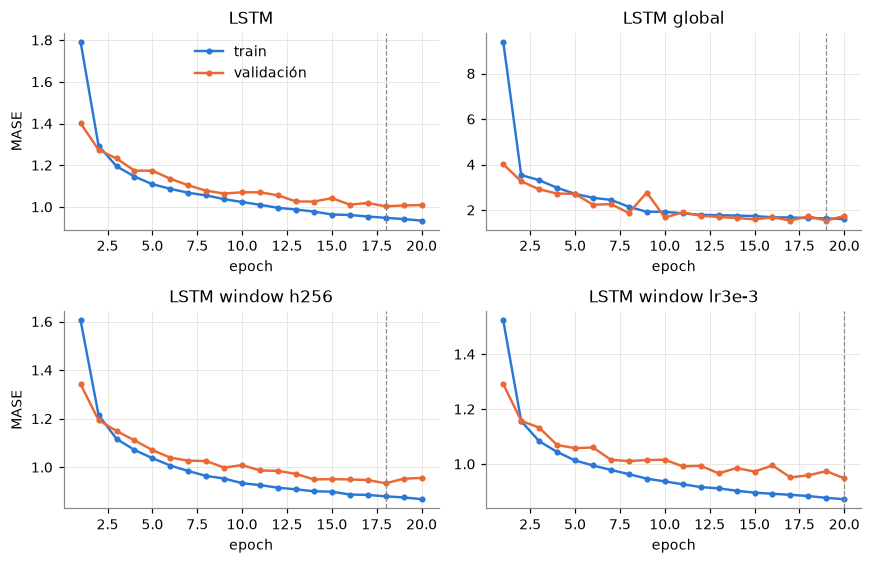

In [23]:
curve_names = [f"lstm_mo_L{best_L}", f"lstm_mo_L{best_L}_global", f"lstm_mo_L{best_L}_{norm_best}_h256",
               f"lstm_mo_L{best_L}_{norm_best}_lr3e-3"]
fig, axes = plt.subplots(2, 2, figsize=(8, 5.2))       # sin eje y compartido: la normalización global escala distinto
for ax, n in zip(axes.flat, curve_names):
    h = pd.DataFrame(ITER[n]["history"])
    ax.plot(h.epoch, h.train_loss, color=PAL[0], marker="o", ms=3, label="train")
    ax.plot(h.epoch, h.val_MASE, color=PAL[1], marker="o", ms=3, label="validación")
    ax.axvline(ITER[n]["best_epoch"], color=GRAY, lw=0.8, ls="--")
    ax.set(title=n.replace(f"lstm_mo_L{best_L}", "LSTM").replace("_", " ") or "LSTM base", xlabel="epoch")
for ax in axes[:, 0]: ax.set_ylabel("MASE")
axes[0, 0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "curvas_perdida.png", dpi=150); plt.show()

### 5.3 Estrategias multi-paso con la LSTM

Las tres estrategias usan la mejor configuración de la LSTM (L, normalización, tamaño): autorregresiva,
multi-salida y encoder–decoder (seq2seq con calendario futuro en el decoder).

In [24]:
lstm_names = [n for n in ITER if n.startswith("lstm_mo")]
best_lstm = best_of(lstm_names)
LSTM_CFG = {k: ITER[best_lstm]["cfg"][k] for k in ("L", "hidden", "layers", "dropout", "norm", "lr", "bs", "months")}
print("mejor LSTM en validación:", best_lstm, LSTM_CFG)
for kind in ("lstm_ar", "seq2seq"):
    run_iter(f"{kind}_best", kind=kind, **LSTM_CFG)

mejor LSTM en validación: lstm_mo_L336_window_h256 {'L': 336, 'hidden': 256, 'layers': 2, 'dropout': 0.1, 'norm': 'window', 'lr': 0.001, 'bs': 512, 'months': 30}
lstm_ar_best             val MASE 0.9118 | epochs 20 (mejor 19) | 1159s | params 798,979
seq2seq_best             val MASE 0.9575 | epochs 20 (mejor 20) | 1113s | params 1,597,699


### 5.4 Modelos de NeuralForecast y Chronos-Bolt

NeuralForecast recibe un DataFrame largo `(unique_id, ds, y)` más las columnas de calendario. Cada modelo se
entrena una vez con `fit(df ≤ 2014-09-30, val_size=2208)`: train hasta junio y early stopping con jul–sep.
Para pronosticar los 92 orígenes de una vez, cada (cliente, origen) se apila como una serie truncada en el
origen. iTransformer es multivariado (necesita las 100 series juntas), así que se recorre origen por origen.
DeepAR entrena 1500 pasos fijos sin early stopping: su validación es recursiva con 100 trayectorias sobre todas
las ventanas de validación, y cada chequeo tarda minutos en MPS.
Las redes de NeuralForecast usan normalización por ventana (`scaler_type="robust"`; PatchTST además usa RevIN).

In [25]:
from neuralforecast import NeuralForecast
from neuralforecast.models import NHITS, PatchTST, iTransformer, DeepAR
from neuralforecast.losses.pytorch import MAE as NF_MAE, DistributionLoss

NF_STEPS = 20 if FAST else 2000
def nf_common(L, seed=SEED, **over):
    kw = dict(h=H, input_size=L, max_steps=NF_STEPS, val_check_steps=10 if FAST else 100,
              early_stop_patience_steps=3 if not FAST else -1, learning_rate=1e-3, batch_size=64,
              windows_batch_size=512, inference_windows_batch_size=1024, scaler_type="robust", random_seed=seed,
              accelerator=DEVICE.type, devices=1, enable_progress_bar=False, logger=False, enable_model_summary=False)
    return {**kw, **over}

NF_SPECS = {
    "NHITS": (lambda L, s: NHITS(futr_exog_list=CAL_COLS, loss=NF_MAE(), **nf_common(L, s)), "Residual (MLP jerárquico)", "sí (calendario)"),
    "PatchTST": (lambda L, s: PatchTST(patch_len=24, stride=12, hidden_size=128, n_heads=8, encoder_layers=3,
                                       loss=NF_MAE(), **nf_common(L, s)), "Atención", "no"),
    "iTransformer": (lambda L, s: iTransformer(n_series=N_SER, hidden_size=128, n_heads=8, e_layers=2, d_ff=256,
                                               loss=NF_MAE(), **nf_common(L, s)), "Atención", "no"),
    "DeepAR": (lambda L, s: DeepAR(futr_exog_list=CAL_COLS, lstm_n_layers=2, lstm_hidden_size=128,
                                   loss=DistributionLoss("StudentT", level=[80]), trajectory_samples=100,
                                   **nf_common(L, s, inference_windows_batch_size=32, max_steps=20 if FAST else 1500,
                                               val_check_steps=10**6, early_stop_patience_steps=-1)), "Probabilístico", "sí (calendario)"),
}

def nf_frame(t_end, t_start=0, ids=None):
    df = long_df(t_end, t_start)
    cal = pd.DataFrame(CAL[t_start:t_end], columns=CAL_COLS)
    return pd.concat([df, pd.concat([cal] * N_SER, ignore_index=True)], axis=1)

class NFModel(Forecaster):
    def __init__(self, name, L=168, months=30, seed=SEED, tag=None):
        self.base, self.name, self.L, self.months, self.seed = name, tag or name, L, months, seed
        self.family, self.covariates = NF_SPECS[name][1], NF_SPECS[name][2]
        self.strategy = "autorregresiva (muestreo)" if name == "DeepAR" else "multi-salida"
    def fit(self, train_end=T_TR, val_end=T_VA, hist_start=None):
        hs = hist_start_idx(self.months, train_end)
        model = NF_SPECS[self.base][0](self.L, self.seed)
        self.nf = NeuralForecast(models=[model], freq="h")
        self.nf.fit(nf_frame(val_end, hs), val_size=val_end - train_end)
        net = self.nf.models[0]
        self.n_params = sum(p.numel() for p in net.parameters())
        self.n_trainable = sum(p.numel() for p in net.parameters() if p.requires_grad)
        self.peak_mem = mem_mb()
    def _stacked(self, origins, H):
        keep = self.L + 24
        rows, fut = [], []
        for o in origins:
            for i in range(N_SER):
                rows.append((f"{i}|{o}", o - keep, o, i))
        uid = np.repeat([r[0] for r in rows], keep)
        tt = np.concatenate([np.arange(a, b) for _, a, b, _ in rows])
        ii = np.repeat([r[3] for r in rows], keep)
        df = pd.DataFrame({"unique_id": uid, "ds": T_INDEX[tt], "y": Y_kwh[ii, tt]})
        df[CAL_COLS] = CAL[tt]
        tf = np.concatenate([np.arange(b, b + H) for _, a, b, _ in rows])
        fdf = pd.DataFrame({"unique_id": np.repeat([r[0] for r in rows], H), "ds": T_INDEX[tf]})
        fdf[CAL_COLS] = CAL[tf]
        return df, fdf
    def predict(self, origins, H):
        if self.base == "iTransformer":
            outs = []
            for o in origins:
                fc = self.nf.predict(df=nf_frame(o, o - self.L - 24))
                fc["uid"] = fc["unique_id"].astype(int)
                outs.append(fc.sort_values(["uid", "ds"])[self.base].values.reshape(N_SER, 1, H))
            return np.concatenate(outs, 1), None
        df, fdf = self._stacked(origins, H)
        fc = self.nf.predict(df=df, futr_df=fdf if self.covariates != "no" else None)
        fc[["i", "o"]] = fc["unique_id"].str.split("|", expand=True).astype(int)
        fc = fc.sort_values(["i", "o", "ds"])
        point = f"{self.base}-median" if self.base == "DeepAR" else self.base
        P = fc[point].values.reshape(N_SER, len(origins), H)
        Q = None
        if self.base == "DeepAR":
            Q = {0.1: fc[f"{self.base}-lo-80"].values.reshape(P.shape), 0.5: P,
                 0.9: fc[f"{self.base}-hi-80"].values.reshape(P.shape)}
        return P, Q

In [26]:
from chronos import BaseChronosPipeline
CHRONOS_ID = "amazon/chronos-bolt-small" if FAST else "amazon/chronos-bolt-base"

class ChronosModel(Forecaster):
    name, family, strategy, covariates = "Chronos-Bolt", "Fundacional (zero-shot)", "multi-salida (directa)", "no"
    zero_shot = True
    def __init__(self, context=2048):
        self.L = context
    def fit(self, train_end=T_TR, val_end=T_VA, hist_start=None):
        self.pipe = BaseChronosPipeline.from_pretrained(CHRONOS_ID, device_map=DEVICE.type, torch_dtype=torch.float32)
        self.n_params = sum(p.numel() for p in self.pipe.model.parameters()); self.n_trainable = 0
        self.train_time = 0.0
    def predict(self, origins, H):
        ctx = np.stack([Y_kwh[:, o - self.L:o] for o in origins], 1).reshape(-1, self.L)   # (n*n_o, L)
        qs, ms = [], []
        bs = 512 if H <= 64 else 64                      # más de 64 pasos: Bolt itera y usa más memoria
        if DEVICE.type == "mps": torch.mps.empty_cache()
        for k in range(0, len(ctx), bs):
            q, m = self.pipe.predict_quantiles(torch.tensor(ctx[k:k + bs]), prediction_length=H,
                                               quantile_levels=[0.1, 0.5, 0.9])
            qs.append(q.cpu().numpy()); ms.append(m.cpu().numpy())
        q = np.concatenate(qs).reshape(N_SER, len(origins), H, 3)
        self.peak_mem = mem_mb()
        return q[..., 1], {0.1: q[..., 0], 0.5: q[..., 1], 0.9: q[..., 2]}

W1101 21:46:13.021000 63715 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


**Iteración de historia para PatchTST** (3, 12 y 30 meses, en validación) y entrenamiento final de cada
modelo de librería. Chronos no se entrena: solo hace inferencia.

In [27]:
NF_RES = {}
for mo in (3, 12):
    NF_RES[f"PatchTST_{mo}m"] = run_backtests(f"nf_PatchTST_{mo}m", lambda mo=mo: NFModel("PatchTST", months=mo, tag=f"PatchTST_{mo}m"), (("val", 24),))
for nm in NF_SPECS:
    NF_RES[nm] = run_backtests(f"nf_{nm}", lambda nm=nm: NFModel(nm))
CHR = run_backtests("chronos", lambda: ChronosModel(), (("val", 24), ("test", 24), ("test", 168)))

### 5.5 Evaluación final en prueba de los modelos propios (mejor configuración de cada uno)

Se reutilizan los pesos de la mejor iteración (entrenados con datos ≤ 2014-09-30); no se vuelve a entrenar.

In [28]:
def model_from_iter(name, label=None):
    it = ITER[name]; m = TorchModel(label or name, **{k: v for k, v in it["cfg"].items()})
    c = m.cfg
    hs = hist_start_idx(c["months"], T_TR)
    a, b = norm_stats(Y_kwh, c["norm"], T_TR, hs)
    m.a_t = torch.tensor(a, device=DEVICE, dtype=torch.float32); m.b_t = torch.tensor(b, device=DEVICE, dtype=torch.float32)
    m.Ys = (torch.tensor(Y_kwh, device=DEVICE) - m.a_t[:, None]) / m.b_t[:, None]
    m.net = Net(c["kind"], c["L"], c["H"], revin=c["norm"] == "window", hidden=c["hidden"], layers=c["layers"],
                dropout=c["dropout"]).to(DEVICE)
    m.net.load_state_dict({k: v.to(DEVICE) for k, v in it["state"].items()})
    m.n_params, m.n_trainable, m.train_time, m.peak_mem, m.fitted = it["n_params"], it["n_trainable"], it["train_time"], it["peak_mem_MB"], True
    return m

OWN_BEST = {
    "MLP": best_of([n for n in ITER if n.startswith("mlp")]),
    "DLinear": best_of([n for n in ITER if n.startswith("dlinear") and not n.endswith("m")]),
    "NLinear": best_of([n for n in ITER if n.startswith("nlinear")]),
    "TCN": best_of([n for n in ITER if n.startswith("tcn")]),
    "LSTM-MO": best_lstm, "LSTM-AR": "lstm_ar_best", "Seq2seq": "seq2seq_best",
}
for label, it_name in OWN_BEST.items():
    run_backtests(f"own_{label}", lambda label=label, it_name=it_name: model_from_iter(it_name, label), (("test", 24),))
    RESULTS[(label, "val", 24, None)] = {"metrics": {"MASE": ITER[it_name]["val_MASE"]}, "name": label}
print({k: v for k, v in OWN_BEST.items()})

{'MLP': 'mlp_L168', 'DLinear': 'dlinear_L336', 'NLinear': 'nlinear_L336', 'TCN': 'tcn_L336', 'LSTM-MO': 'lstm_mo_L336_window_h256', 'LSTM-AR': 'lstm_ar_best', 'Seq2seq': 'seq2seq_best'}


In [29]:
# H = 168 (una semana) para los lineales propios, con la misma L de su mejor iteración (mín. 336)
for label in ("DLinear", "NLinear"):
    kind = label.lower(); Lh = max(336, ITER[OWN_BEST[label]]["cfg"]["L"])
    run_iter(f"{kind}_H168", kind=kind, L=Lh, H=168, norm=ITER[OWN_BEST[label]]["cfg"]["norm"])
    run_backtests(f"own_{label}_H168", lambda label=label, kind=kind: model_from_iter(f"{kind}_H168", label), (("test", 168),))

dlinear_H168             val MASE 1.0347 | epochs 20 (mejor 19) | 5s | params 113,232
nlinear_H168             val MASE 1.0346 | epochs 20 (mejor 20) | 4s | params 56,616


### 5.6 Estrategias multi-paso: MAE por paso del horizonte (prueba)

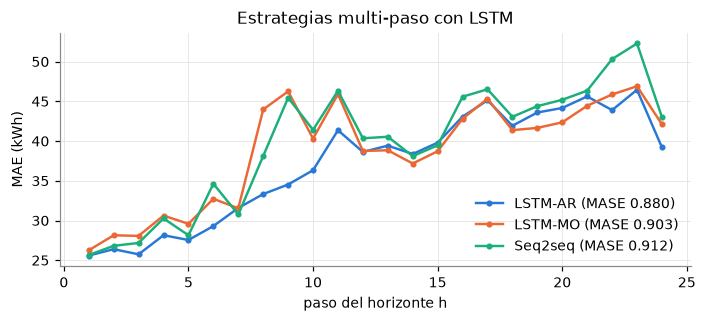

,LSTM-AR,LSTM-MO,Seq2seq
h=1,25.600000,26.260000,25.660000
h=6,29.299999,32.730000,34.639999
h=12,38.639999,38.750000,40.360001
h=18,41.930000,41.380001,43.060001
h=24,39.209999,42.110001,43.020000


In [30]:
fig, ax = plt.subplots(figsize=(6.5, 3))
for k, lab in enumerate(("LSTM-AR", "LSTM-MO", "Seq2seq")):
    r = RESULTS[(lab, "test", 24, None)]
    ax.plot(range(1, 25), r["metrics"]["MAE_paso"], marker="o", ms=3, color=PAL[k],
            label=f"{lab} (MASE {r['metrics']['MASE']:.3f})")
ax.set(xlabel="paso del horizonte h", ylabel="MAE (kWh)", title="Estrategias multi-paso con LSTM")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "estrategias.png", dpi=150); plt.show()
strat_df = pd.DataFrame({lab: RESULTS[(lab, "test", 24, None)]["metrics"]["MAE_paso"][[0, 5, 11, 17, 23]]
                         for lab in ("LSTM-AR", "LSTM-MO", "Seq2seq")}, index=["h=1", "h=6", "h=12", "h=18", "h=24"]).round(2)
strat_df.to_csv(RES / "estrategias.csv"); strat_df

## 7. Resultados del trabajo de CPU (baselines y LightGBM)

In [31]:
t_wait = time.time()
cpu_out = cpu_future.result()
print(f"esperé {time.time() - t_wait:.0f}s al hilo de CPU")
for r in sum(cpu_out.values(), []):
    RESULTS[(r["name"], r["split"], r["H"], r["retrain"])] = r

esperé 0s al hilo de CPU


### 7.1 Modelo local contra global (10 clientes)

El mejor modelo propio (según validación) se entrena una vez por cliente para 10 clientes elegidos con semilla
fija, con la misma configuración. Se compara la MASE de prueba de esos 10 clientes contra la del modelo global.

In [32]:
own_val = {lab: ITER[n]["val_MASE"] for lab, n in OWN_BEST.items()}
best_own = min(own_val, key=own_val.get)
print("mejor modelo propio en validación:", best_own, round(own_val[best_own], 4))
LOCAL_IDX = sorted(np.random.default_rng(SEED).choice(N_SER, 10, replace=False).tolist())

def local_job():
    rows = []
    cfg = {k: v for k, v in ITER[OWN_BEST[best_own]]["cfg"].items()}
    glob = RESULTS[(best_own, "test", 24, None)]["metrics"]["MASE_cliente"]
    o = split_origins("test")
    for i in LOCAL_IDX:
        m = TorchModel(f"local_{i}", series=[i], **cfg); t0 = time.time(); m.fit(); tt = time.time() - t0
        P, _ = m.predict(o, H)
        A = np.abs(np.maximum(P, 0) - truth(o, H)[[i]])
        rows.append({"cliente": CLIENTS[i], "consumo medio kWh": float(mean_train[i]),
                     "MASE local": float(A.mean() / MASE_SCALE[i]), "MASE global": float(glob[i]),
                     "params local": m.n_params, "train s": tt, "ventanas": m.n_windows})
    return pd.DataFrame(rows)
local_df = cached(f"local_{best_own}", local_job)
local_df["mejora global %"] = 100 * (1 - local_df["MASE global"] / local_df["MASE local"])
local_df.to_csv(RES / "local_vs_global.csv", index=False)
print(local_df.round(3).to_string(index=False))
print("MASE media  local %.3f | global %.3f" % (local_df["MASE local"].mean(), local_df["MASE global"].mean()))

mejor modelo propio en validación: DLinear 0.8569
cliente  consumo medio kWh  MASE local  MASE global  params local  train s  ventanas  mejora global %
 MT_046            131.096       0.825        0.836         16176    1.138     21529           -1.253
 MT_050            164.507       0.749        0.763         16176    0.934     21529           -1.803
 MT_083             71.758       0.756        0.768         16176    1.032     21529           -1.641
 MT_174            148.192       1.301        1.269         16176    0.685     21529            2.465
 MT_247            466.957       0.674        0.669         16176    1.089     21529            0.759
 MT_268            238.071       0.855        0.845         16176    1.087     21529            1.118
 MT_279          11479.718       0.990        0.963         16176    1.076     21529            2.746
 MT_319             94.970       0.960        0.948         16176    1.119     21529            1.308
 MT_357           1874.209      

### 7.2 Reentrenamiento mensual (ventana expandible)

El mejor modelo de deep learning (según validación) y el mejor baseline (según validación) se vuelven a
entrenar al inicio de octubre, noviembre y diciembre. En cada caso se usan todos los datos previos, y los
últimos 92 días como validación.

In [33]:
def factory_of(label):
    if label in OWN_BEST:
        it = ITER[OWN_BEST[label]]
        return lambda seed=SEED: TorchModel(label, seed=seed, **it["cfg"])
    if label in NF_SPECS:
        return lambda seed=SEED: NFModel(label, seed=seed)
    return STATS_SPECS[label]

dl_labels = list(OWN_BEST) + list(NF_SPECS)
val_mase = {k[0]: r["metrics"]["MASE"] for k, r in RESULTS.items() if k[1] == "val" and k[2] == 24}
best_dl = min(dl_labels, key=lambda l: val_mase[l])
best_base = min(STATS_SPECS, key=lambda l: val_mase[l])
print("mejor DL en validación:", best_dl, "| mejor baseline en validación:", best_base)
retrain_targets = [best_dl, best_base] + (["MSTL"] if best_base != "MSTL" else [])
for lab in retrain_targets:
    r = cached(f"retrain_{lab}", lambda lab=lab: backtest(factory_of(lab)(), "test", 24, retrain="monthly"))
    RESULTS[(lab, "test", 24, "monthly")] = r
retrain_df = pd.DataFrame([{"modelo": lab, "MASE una vez": RESULTS[(lab, "test", 24, None)]["metrics"]["MASE"],
                            "MASE reentreno mensual": RESULTS[(lab, "test", 24, "monthly")]["metrics"]["MASE"],
                            "train s (3 reentrenos)": RESULTS[(lab, "test", 24, "monthly")]["train_time"]}
                           for lab in retrain_targets]).round(4)
retrain_df.to_csv(RES / "reentrenamiento.csv", index=False); retrain_df

mejor DL en validación: iTransformer | mejor baseline en validación: MSTL


,modelo,MASE una vez,MASE reentreno mensual,train s (3 reentrenos)
0,iTransformer,0.7917,0.7902,637.6813
1,MSTL,0.9279,0.9257,14.0109


### 7.3 Sensibilidad a la semilla (mejor modelo de deep learning, 3 semillas)

In [34]:
def seeds_job():
    out = []
    for s in (SEED, SEED + 1, SEED + 2):
        if s == SEED:
            out.append(RESULTS[(best_dl, "test", 24, None)]["metrics"]["MASE"]); continue
        m = factory_of(best_dl)(seed=s); m.name = f"{best_dl}_s{s}"
        out.append(backtest(m, "test", 24)["metrics"]["MASE"])
    return out
seed_mase = cached(f"seeds_{best_dl}", seeds_job)
print(f"{best_dl}: MASE por semilla {np.round(seed_mase, 4)} | media {np.mean(seed_mase):.4f} ± {np.std(seed_mase, ddof=1):.4f}")

iTransformer: MASE por semilla [0.7917 0.7843 0.7785] | media 0.7849 ± 0.0066


## 8. Comparación de resultados

In [35]:
MODELS = list(STATS_SPECS) + ["LightGBM"] + list(OWN_BEST) + list(NF_SPECS) + ["Chronos-Bolt"]
rows = []
for nm in MODELS:
    r = RESULTS[(nm, "test", 24, None)]; m = r["metrics"]
    r168 = RESULTS.get((nm, "test", 168, None))
    rows.append({"modelo": nm, "familia": r["family"], "L": r["L"], "estrategia": r["strategy"], "covariables": r["covariates"],
                 "params": r["n_params"], "entrenables": r["n_trainable"],
                 "train s": round(r["train_time"], 1), "infer s": round(r["infer_time"], 1), "hardware": r["hardware"],
                 "MAE": m["MAE"], "RMSE": m["RMSE"], "WAPE": m["WAPE"], "MAPE %": m["MAPE"], "MASE": m["MASE"],
                 "MASE H=168": r168["metrics"]["MASE"] if r168 else np.nan, "MASE 22–28 dic": m["MASE_navidad"],
                 "pinball": m.get("pinball", np.nan), "cobertura P10–P90": m.get("cobertura_80", np.nan),
                 "val MASE": val_mase.get(nm, np.nan)})
comp = pd.DataFrame(rows).sort_values("MASE").reset_index(drop=True)
comp.to_csv(RES / "comparacion.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
comp.round(3)

,modelo,familia,L,estrategia,covariables,params,entrenables,train s,infer s,hardware,MAE,RMSE,WAPE,MAPE %,MASE,MASE H=168,MASE 22–28 dic,pinball,cobertura P10–P90,val MASE
0,Chronos-Bolt,Fundacional (zero-shot),2048,multi-salida (directa),no,205292928,0,0.0,60.1,Apple M5 Pro (MPS),30.506,195.855,0.059,7.760,0.738,0.919,1.332,0.247,0.799,0.756
1,LightGBM,Árboles,168,directa (h como variable),sí,765000,765000,763.5,59.1,"Apple M5 Pro (CPU, 11 hilos)",32.316,169.634,0.063,7.991,0.788,NaN,1.395,NaN,NaN,0.805
2,iTransformer,Atención,168,multi-salida,no,289944,289944,223.7,1.9,Apple M5 Pro (MPS),33.216,171.771,0.064,8.604,0.792,NaN,1.383,NaN,NaN,0.805
3,DLinear,Lineal,336,multi-salida,no,16176,16176,4.4,0.0,Apple M5 Pro (MPS),35.582,185.655,0.069,9.927,0.869,0.995,1.857,NaN,NaN,0.857
4,NLinear,Lineal,336,multi-salida,no,8088,8088,3.4,0.0,Apple M5 Pro (MPS),35.739,186.126,0.069,10.005,0.873,0.987,1.838,NaN,NaN,0.862
5,LSTM-AR,Recurrente,336,autorregresiva,sí (calendario),798979,798979,1159.5,16.0,Apple M5 Pro (MPS),37.052,191.949,0.072,9.280,0.880,NaN,1.494,NaN,NaN,0.912
6,PatchTST,Atención,168,multi-salida,no,445467,445464,334.0,0.9,Apple M5 Pro (MPS),36.784,185.833,0.071,9.871,0.883,NaN,1.630,NaN,NaN,0.886
7,TCN,Convolucional,336,multi-salida,sí (calendario),75928,75928,159.2,0.3,Apple M5 Pro (MPS),37.220,179.496,0.072,9.891,0.893,NaN,1.519,NaN,NaN,0.900
8,LSTM-MO,Recurrente,336,multi-salida,sí (calendario),913690,913690,2769.0,34.2,Apple M5 Pro (MPS),38.742,189.597,0.075,9.807,0.903,NaN,1.317,NaN,NaN,0.934
9,Seq2seq,Encoder–decoder,336,encoder–decoder,sí (calendario),1597699,1597699,1113.0,11.4,Apple M5 Pro (MPS),39.584,200.249,0.077,9.544,0.912,NaN,1.406,NaN,NaN,0.957


In [36]:
sn = comp.set_index("modelo").loc["SeasonalNaive24"]
best_row = comp.iloc[0]
print(f"ganador: {best_row.modelo} MASE {best_row.MASE:.3f} vs seasonal naive 24 {sn.MASE:.3f} "
      f"→ {100*(1-best_row.MASE/sn.MASE):.1f}% menos error")
per_client = pd.DataFrame({nm: RESULTS[(nm, "test", 24, None)]["metrics"]["MAE_cliente"] for nm in MODELS}, index=CLIENTS)
per_client.to_csv(RES / "mae_por_cliente.csv")
pd.DataFrame({nm: RESULTS[(nm, "test", 24, None)]["metrics"]["RMSE_cliente"] for nm in MODELS}, index=CLIENTS).to_csv(RES / "rmse_por_cliente.csv")
pd.DataFrame({nm: RESULTS[(nm, "test", 24, None)]["metrics"]["MAE_paso"] for nm in MODELS}, index=range(1, 25)).to_csv(RES / "mae_por_paso.csv")
pd.DataFrame({nm: RESULTS[(nm, "test", 24, None)]["metrics"]["MAE_hora"] for nm in MODELS}, index=range(24)).to_csv(RES / "mae_por_hora.csv")

ganador: Chronos-Bolt MASE 0.738 vs seasonal naive 24 1.036 → 28.7% menos error


**MAPE y clientes de consumo cercano a cero.** El MAPE divide entre el valor real: en horas con consumo
casi nulo, un error pequeño en kWh produce porcentajes enormes.

In [37]:
mape_c = RESULTS[(best_row.modelo, "test", 24, None)]["metrics"]["MAPE_cliente"]
low = np.argsort(mean_train)[:5]
print(pd.DataFrame({"cliente": np.array(CLIENTS)[low], "consumo medio kWh": mean_train[low].round(3),
                    "MAPE %": mape_c[low].round(1), "MASE": RESULTS[(best_row.modelo, "test", 24, None)]["metrics"]["MASE_cliente"][low].round(3)}).to_string(index=False))
print("MAPE mediano por cliente %.1f%% | máximo %.1f%%" % (np.median(mape_c), mape_c.max()))

cliente  consumo medio kWh  MAPE %  MASE
 MT_026          20.865000     8.8 0.694
 MT_063          22.674000     8.8 0.648
 MT_149          23.488001     3.6 0.562
 MT_022          27.096001    11.4 0.605
 MT_150          27.646000     3.2 0.795
MAPE mediano por cliente 6.4% | máximo 36.8%


### Gráficas: frontera de Pareto, MAE por paso e historia de entrenamiento

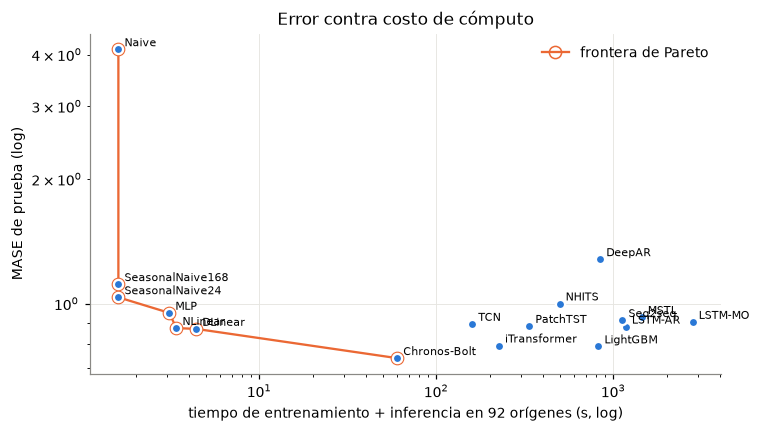

In [38]:
# Eje x: entrenamiento + inferencia de los 92 orígenes. Chronos (zero-shot) solo tiene inferencia, y con
# el tiempo de entrenamiento solo, quedaría en x = 0, fuera de la escala log.
fig, ax = plt.subplots(figsize=(7, 4))
tt = (comp["train s"] + comp["infer s"]).clip(lower=0.05)
ax.scatter(tt, comp.MASE, s=36, color=PAL[0], edgecolor="white", linewidth=1.5, zorder=3)
order = np.argsort(tt.values); front, best_so_far = [], np.inf
for k in order:
    if comp.MASE.iloc[k] < best_so_far: best_so_far = comp.MASE.iloc[k]; front.append(k)
ax.plot(tt.iloc[front], comp.MASE.iloc[front], color=PAL[1], lw=1.5, marker="o", ms=8, mfc="none", label="frontera de Pareto")
for k in range(len(comp)):
    ax.annotate(comp.modelo.iloc[k], (tt.iloc[k], comp.MASE.iloc[k]), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set(xlabel="tiempo de entrenamiento + inferencia en 92 orígenes (s, log)", ylabel="MASE de prueba (log)",
       title="Error contra costo de cómputo")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "pareto.png", dpi=150); plt.show()

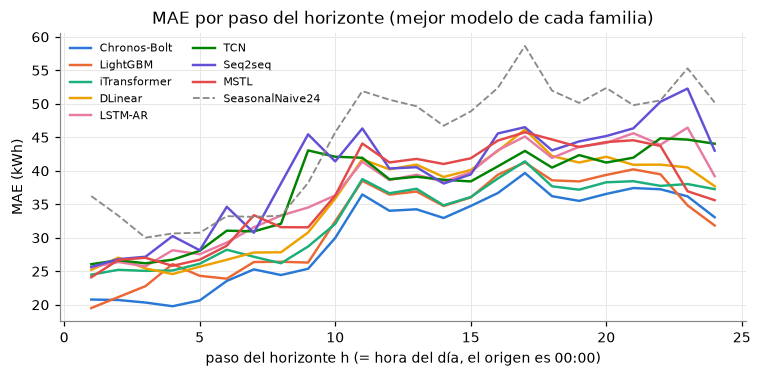

In [39]:
fam_best = comp.groupby("familia", sort=False).head(1).modelo.tolist()[:8]
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, nm in enumerate(fam_best):
    ax.plot(range(1, 25), RESULTS[(nm, "test", 24, None)]["metrics"]["MAE_paso"], color=PAL[k], lw=1.6, label=nm)
ax.plot(range(1, 25), RESULTS[("SeasonalNaive24", "test", 24, None)]["metrics"]["MAE_paso"], color=GRAY, ls="--", lw=1.2, label="SeasonalNaive24")
ax.set(xlabel="paso del horizonte h (= hora del día, el origen es 00:00)", ylabel="MAE (kWh)",
       title="MAE por paso del horizonte (mejor modelo de cada familia)")
ax.legend(frameon=False, fontsize=7, ncol=2); fig.tight_layout(); fig.savefig(FIG / "mae_por_paso.png", dpi=150); plt.show()

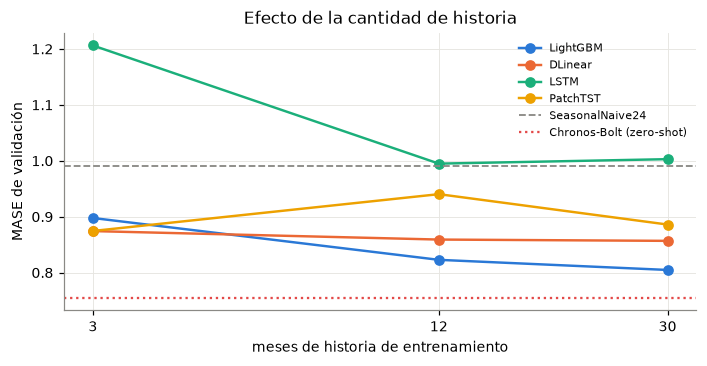

,LightGBM,DLinear,LSTM,PatchTST,SeasonalNaive24
meses,,,,,
3,0.8978,0.8744,1.2063,0.8745,0.9899
12,0.8229,0.8592,0.9950,0.9404,0.9899
30,0.8048,0.8569,1.0030,0.8860,0.9899


In [40]:
hist_curves = {
    "LightGBM": {3: "LightGBM_3m", 12: "LightGBM_12m", 30: "LightGBM"},
    "DLinear": {3: "dlinear_L336_3m", 12: "dlinear_L336_12m", 30: "dlinear_L336"},
    "LSTM": {3: f"lstm_mo_L{best_L}_3m", 12: f"lstm_mo_L{best_L}_12m", 30: f"lstm_mo_L{best_L}"},
    "PatchTST": {3: "PatchTST_3m", 12: "PatchTST_12m", 30: "PatchTST"},
}
def val_of(n):
    return ITER[n]["val_MASE"] if n in ITER else val_mase[n]
hist_tab = pd.DataFrame({k: {m: val_of(n) for m, n in d.items()} for k, d in hist_curves.items()})
hist_tab["SeasonalNaive24"] = val_mase["SeasonalNaive24"]
hist_tab.index.name = "meses"; hist_tab.to_csv(RES / "historia.csv")
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for k, col in enumerate(["LightGBM", "DLinear", "LSTM", "PatchTST"]):
    ax.plot(hist_tab.index, hist_tab[col], marker="o", color=PAL[k], label=col)
ax.axhline(val_mase["SeasonalNaive24"], color=GRAY, ls="--", lw=1.2, label="SeasonalNaive24")
ax.axhline(val_mase["Chronos-Bolt"], color=PAL[7], ls=":", lw=1.5, label="Chronos-Bolt (zero-shot)")
ax.set_xscale("log"); ax.set_xticks([3, 12, 30]); ax.set_xticklabels(["3", "12", "30"])
ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
ax.set(xlabel="meses de historia de entrenamiento", ylabel="MASE de validación", title="Efecto de la cantidad de historia")
ax.legend(frameon=False, fontsize=7); fig.tight_layout(); fig.savefig(FIG / "historia.png", dpi=150); plt.show()
hist_tab.round(4)

### Pronóstico probabilístico y semana de Navidad

      modelo  MASE  pinball  cobertura P10–P90
Chronos-Bolt 0.738    0.247              0.799
      DeepAR 1.280    0.458              0.579


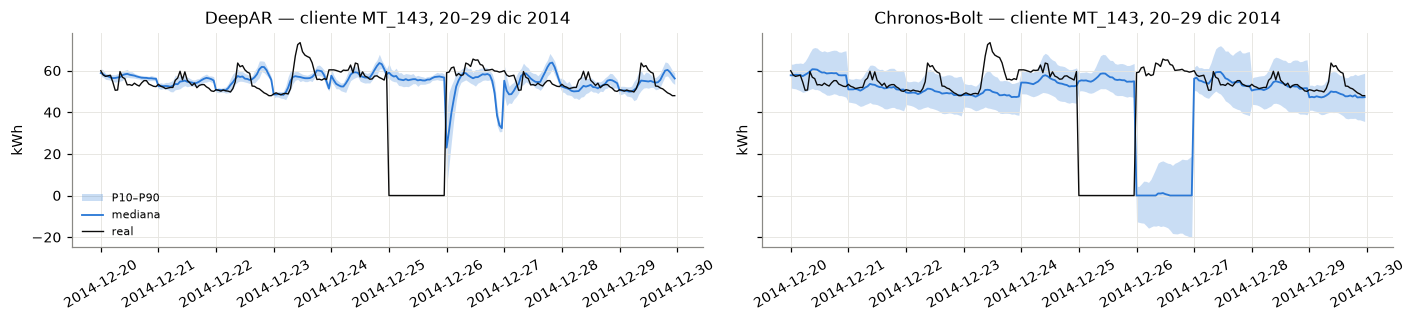

In [41]:
prob = comp[comp["pinball"].notna()][["modelo", "MASE", "pinball", "cobertura P10–P90"]]
print(prob.round(3).to_string(index=False))
ci = int(np.argsort(mean_train)[N_SER // 2])                         # un cliente de consumo mediano
o_te = split_origins("test")
d0 = int(np.where(T_INDEX[o_te] == pd.Timestamp("2014-12-20"))[0][0])
sel = slice(d0, d0 + 10)
fig, axes = plt.subplots(1, 2, figsize=(13, 3), sharey=True)
t_axis = T_INDEX[(o_te[sel][:, None] + np.arange(H)).ravel()]
for ax, nm in zip(axes, ["DeepAR", "Chronos-Bolt"]):
    r = RESULTS[(nm, "test", 24, None)]
    ax.fill_between(t_axis, r["Q"][0.1][ci, sel].ravel(), r["Q"][0.9][ci, sel].ravel(), color=PAL[0], alpha=0.25, lw=0, label="P10–P90")
    ax.plot(t_axis, r["P"][ci, sel].ravel(), color=PAL[0], lw=1.2, label="mediana")
    ax.plot(t_axis, truth(o_te[sel], H)[ci].ravel(), color="#0b0b0b", lw=0.9, label="real")
    ax.set(title=f"{nm} — cliente {CLIENTS[ci]}, 20–29 dic 2014", ylabel="kWh")
    ax.tick_params(axis="x", labelrotation=30)
axes[0].legend(frameon=False, fontsize=7); fig.tight_layout(); fig.savefig(FIG / "probabilistico.png", dpi=150); plt.show()

In [42]:
xmas_cmp = comp[["modelo", "MASE", "MASE 22–28 dic"]].copy()
xmas_cmp["deterioro %"] = 100 * (xmas_cmp["MASE 22–28 dic"] / xmas_cmp["MASE"] - 1)
print(xmas_cmp.round(3).to_string(index=False))

          modelo  MASE  MASE 22–28 dic  deterioro %
    Chronos-Bolt 0.738           1.332       80.419
        LightGBM 0.788           1.395       77.065
    iTransformer 0.792           1.383       74.741
         DLinear 0.869           1.857      113.797
         NLinear 0.873           1.838      110.618
         LSTM-AR 0.880           1.494       69.840
        PatchTST 0.883           1.630       84.583
             TCN 0.893           1.519       70.057
         LSTM-MO 0.903           1.317       45.885
         Seq2seq 0.912           1.406       54.209
            MSTL 0.928           2.030      118.734
             MLP 0.950           1.434       50.960
           NHITS 1.000           1.520       51.918
 SeasonalNaive24 1.036           2.167      109.263
SeasonalNaive168 1.114           1.601       43.654
          DeepAR 1.280           2.005       56.590
           Naive 4.118           3.993       -3.026


### Archivo de pronósticos de prueba

`results/pronosticos_prueba.parquet`, con las columnas `unique_id, ds, modelo, y_hat`. Contiene todos los modelos
de la tabla con H = 24 en los 92 orígenes de prueba, más `cutoff` (el origen) para distinguir los horizontes.

In [43]:
frames = []
o_te = split_origins("test"); tgt = o_te[:, None] + np.arange(H)
for nm in MODELS:
    P = RESULTS[(nm, "test", 24, None)]["P"]
    frames.append(pd.DataFrame({"unique_id": np.repeat(CLIENTS, tgt.size), "ds": np.tile(T_INDEX[tgt.ravel()], N_SER),
                                "cutoff": np.tile(np.repeat(T_INDEX[o_te], H), N_SER), "modelo": nm,
                                "y_hat": P.ravel().astype(np.float32)}))
fc_all = pd.concat(frames, ignore_index=True)
fc_all.to_parquet(RES / "pronosticos_prueba.parquet", index=False)
pd.DataFrame({"unique_id": np.repeat(CLIENTS, tgt.size), "ds": np.tile(T_INDEX[tgt.ravel()], N_SER),
              "y": truth(o_te, H).ravel()}).to_parquet(RES / "reales_prueba.parquet", index=False)
print(fc_all.shape, fc_all.modelo.nunique(), "modelos")

(3753600, 5) 17 modelos


In [44]:
summary = {"clientes_filtrados": len(kept), "clientes_usados": N_SER, "horas_por_serie": T,
           "obs_panel_completo": int(len(kept) * T), "obs_panel_usado": int(N_SER * T),
           "ventanas": win_table.to_dict(), "escalas": scale_stats, "escalas_completo": scale_stats_all,
           "dst": dst_log, "navidad": xmas_df.astype(str).to_dict("records"), "dow_rel": dow_table.to_dict(),
           "best_L": best_L, "norm_best": norm_best, "best_lstm": best_lstm, "own_best": OWN_BEST,
           "best_own": best_own, "best_dl": best_dl, "best_base": best_base, "seed_mase": seed_mase,
           "local_mean": local_df[["MASE local", "MASE global"]].mean().to_dict(),
           "hardware": HARDWARE_GPU, "device": str(DEVICE)}
json.dump(summary, open(RES / "resumen.json", "w"), indent=1, default=str)
CPU_POOL.shutdown()
print(json.dumps({k: summary[k] for k in ("best_L", "norm_best", "best_own", "best_dl", "best_base")}, default=str))

{"best_L": 336, "norm_best": "window", "best_own": "DLinear", "best_dl": "iTransformer", "best_base": "MSTL"}
